# Q&A signals: how management handled the question

FinBERT and BERTopic say what analysts ask about and how it sounds. This notebook measures how the answer went: was a number asked for and given, how hedged was it, did management decline, did it stay on the question, and did the analyst come back.

Part 1 needs only `exchanges.parquet`. Part 2 adds five signals built on the FinBERT and BERTopic tables. Part 3 follows tutor notebooks 6 and 7: topic attention, a shortlist of the exchanges where the signals stack, Gemma 3 extraction on that shortlist, and an evidence table. Three signals that were tried and dropped close the notebook. Outputs are written next to the corpus tables: `signals`, `signals_quarter`, `signals_topic`, `signals_matched`, `signals_attention` and `signals_review`.

## The five signals

| # | signal | measured on | column |
|---|---|---|---|
| 1 | metric request coverage | question asks for a figure, answer has one | `q_asks_figure`, `a_n_figures` |
| 2 | hedging | softening words per 100 answer words | `a_hedges_per_100w` |
| 3 | deflection | management openly declines to answer | `a_deflects` |
| 4 | Q&A alignment | cosine between question and answer embeddings | `qa_alignment` |
| 5 | follow up pressure | same analyst takes the next slot, or says they are coming back | `is_followup` |

Four are regular expressions. Only alignment needs a model, the same bge-small BERTopic uses. The full run takes about 30 seconds on a CPU.

## Setup

In [1]:
#find_spec("google.colab") raises when google itself is not installed
#Colab always has google.colab loaded already, so sys.modules is enough
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q sentence-transformers==5.5.1

Only needed on Colab. sentence-transformers is for signal 4, everything else is pandas and `re`.

## Import Libraries

In [2]:
import json
import os
import re

import numpy as np
import pandas as pd
#shows several tables from one cell
from IPython.display import display

#library for signal 4 only
from sentence_transformers import SentenceTransformer

#talks to the local Ollama server in part 3
import requests

#exact test for the headline finding, scipy already comes with scikit-learn
from scipy.stats import fisher_exact

#libraries for the plots
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

## Data paths and Common Variables

In [3]:
#where the corpus build wrote its tables. Change this on Colab
DATA_OUTPUT = "data/corpus"
EXCHANGES_FILE = f"{DATA_OUTPUT}/exchanges.parquet"
#the source URL of each transcript, for the read-first sheet
DOCUMENTS_FILE = f"{DATA_OUTPUT}/documents.parquet"
#one row per exchange, and one per bank, audience and quarter
SIGNALS_FILE = f"{DATA_OUTPUT}/signals.parquet"
SIGNALS_QUARTER_FILE = f"{DATA_OUTPUT}/signals_quarter.parquet"

#the embedder topics.py uses, so the two stages see the same geometry
EMBEDDINGS = "BAAI/bge-small-en-v1.5"
#if false, qa_alignment is left empty and no model is loaded
RUN_ALIGNMENT = True
#quarters of history a bank needs before a quarter gets a z-score
MIN_HISTORY = 4
#a quarter with fewer questions than this gets no z-score and leaves the history
#one fixed income exchange gave a deflection z of 9.91
MIN_N = 10
#a next-slot question this short with no question mark is a sign-off or a one
#word reply ("Great. Thank you very much."), not the analyst coming back
SIGN_OFF_WORDS = 12
#pinned once for the within-analyst shuffle
SEED = 42
#shuffles behind the headline p-value, enough for a p near 0.001
N_SHUFFLES = 1000

#every signal and every check is split by bank, in this order
BANKS = ["hsbc", "barclays"]
BANK_NAMES = {"hsbc": "HSBC", "barclays": "Barclays"}
#one colour per bank, the same in every plot
BANK_COLOURS = {"hsbc": "#2a78d6", "barclays": "#eb6834"}
TEXT_PRIMARY, TEXT_SECONDARY = "#0b0b0b", "#52514e"
GRID_COLOUR, AXIS_COLOUR = "#e1e0d9", "#c3c2b7"
#blue below the bank's own history, red above, grey for no change
Z_COLOURS = LinearSegmentedColormap.from_list("z", ["#2a78d6", "#f0efec", "#e34948"])
#plain names for the BERTopic topics, written from their top words and sample questions
#the broad and filler topics are named as such rather than given a subject
TOPIC_NAMES = {-1: "No single topic",
               0: "Hong Kong, China and group strategy (broad)",
               1: "Acknowledgement, no subject",
               2: "Structural hedge and rate sensitivity",
               3: "UK business and cards (broad)",
               4: "RWAs and the Investment Bank",
               5: "Mortgages, lending and UK rates",
               6: "Clarification, no subject",
               7: "AT1, legacy capital and issuance",
               8: "Costs and investment spend",
               9: "Capital and buybacks",
               10: "Deposits and deposit pricing",
               11: "Net interest income and margin guidance",
               12: "Guidance against consensus (broad)"}
#broad or no subject, so not comparable between banks in the peer view
PEER_EXCLUDED_TOPICS = [0, 1, 3, 6, 12]
#a topic needs this many questions at a bank before it is plotted for that bank
MIN_TOPIC_QUESTIONS = 10

#tables written by the FinBERT and BERTopic stages, read in part 2
SENTIMENT_FILE = f"{DATA_OUTPUT}/sentiment.parquet"
SENTIMENT_EXCHANGES_FILE = f"{DATA_OUTPUT}/sentiment_exchanges.parquet"
TOPICS_FILE = f"{DATA_OUTPUT}/topics.parquet"
TOPIC_INFO_FILE = f"{DATA_OUTPUT}/topic_info.parquet"
TURNS_FILE = f"{DATA_OUTPUT}/turns.parquet"
#what part 2 writes
SIGNALS_TOPIC_FILE = f"{DATA_OUTPUT}/signals_topic.parquet"
SIGNALS_MATCHED_FILE = f"{DATA_OUTPUT}/signals_matched.parquet"

#topic 1 is "thank you", "okay great", median 5 words. Not a subject
ACKNOWLEDGEMENT_TOPICS = [1]
#an analyst needs this many questions before their own baseline means anything
MIN_ANALYST_QUESTIONS = 5

#what part 3 writes. The jsonl is a cache, a rerun skips done exchanges
SIGNALS_ATTENTION_FILE = f"{DATA_OUTPUT}/signals_attention.parquet"
SIGNALS_REVIEW_FILE = f"{DATA_OUTPUT}/signals_review.parquet"
LLM_CACHE_FILE = f"{DATA_OUTPUT}/signals_llm.jsonl"

#exchanges per bank sent to the LLM, the shortlist and not the corpus
SHORTLIST_SIZE = 15
#if false, only what is already in the cache is used
RUN_EXTRACTION = True
#Gemma 3 4B as in tutor notebook 6. Ollama locally, transformers on Colab
LLM_OLLAMA = "gemma3:4b"
LLM_HF = "google/gemma-3-4b-it"
OLLAMA_URL = "http://localhost:11434/api/generate"


# Common Functions

## The patterns

Every pattern was checked against the exchanges before it went in. The phrase that fired is kept on the row, so any flag can be checked against the transcript.

In [4]:
#a figure is a number with a unit. Bare numbers are years, pages and quarters
#the verbal ranges are how guidance is often given ("mid-single digit")
FIGURE = re.compile(
    r"[£$€]\s?\d[\d,.]*"
    r"|\b\d[\d,.]*\s?(?:%|per ?cent\b|percent\b|bps\b|bp\b|basis points?\b|"
    r"bn\b|billion\b|m\b|million\b|pence\b|p\b|x\b)"
    r"|\b(?:low|mid|high)[- ](?:single|double)[- ]digits?\b"
    r"|\b(?:low|mid|high)[- ](?:teens|twenties|thirties)\b",
    re.I)

#the analyst asked for a quantity, a range or guidance
ASKS_FOR_FIGURE = re.compile(
    r"\b(?:guidance|guide|target|outlook|quantify|sizing|size|ballpark|"
    r"how (?:much|many|big|large)|what (?:sort of )?(?:level|number|range|figure)|"
    r"basis points|bps|percent)\b|%",
    re.I)

#"around" and "roughly" are left out, they qualify a figure
#and would count the same answer as both specific and vague
HEDGE = re.compile(
    r"\b(?:may|might|could|perhaps|possibly|uncertain(?:ty|ties)?|unclear|"
    r"depends?|dependent|depending|assum(?:e|es|ing|ption|ptions)|hopefully|"
    r"volatil(?:e|ity)|(?:difficult|hard) to (?:say|call|predict|tell)|"
    r"we'll see|remains to be seen|time will tell|too early)\b",
    re.I)

#"I'm not going to" is always followed by a refusal verb in this corpus
DEFLECTION = re.compile(
    r"\b(?:(?:i'm|i am|we're|we are) not going to (?:give|guide|comment|call|throw|"
    r"provide|speculate|disclose|get into|go into|put a number)"
    r"|(?:don't|do not|won't|wouldn't|would not) (?:want to )?(?:guide|give guidance|"
    r"comment|speculate|disclose)"
    r"|too early to (?:say|tell|comment|call)"
    r"|(?:can't|cannot) (?:comment|disclose|share|give you)"
    r"|(?:we|i) haven't (?:given|disclosed)"
    r"|not in a position to"
    r"|(?:we'll|we will) come back to you"
    r"|take (?:it|that) (?:offline|out of the room))",
    re.I)

#the analyst saying they are returning to something already answered
PUSHBACK = re.compile(
    r"\b(?:follow[- ]?(?:up|on)|come back (?:on|to)|going back to|to clarify|"
    r"just to (?:be clear|push|press)|sorry to (?:come back|push|labour|belabour)|"
    r"(?:push|press)(?:ing)? (?:you|a bit|a little))\b",
    re.I)

#same politeness list as topics.py, so alignment sees what BERTopic sees
BOILERPLATE = re.compile(
    r"\b(thanks?( you)?( very much)?( for taking my questions?)?|"
    r"good (morning|afternoon|evening)( everybody| everyone| both| all)?|"
    r"two questions from me|a couple of questions|just a quick one|"
    r"if i (may|could)|morning both|can you hear me|first of all)\b[,.]?\s*",
    re.I)

Deflection hits by opening words, over the whole corpus: "I'm not going to" 59, "we haven't given" 18, "too early to" 15, "don't disclose" 15, "we'll come back to you" 8, "can't comment" 8.

## Small helpers

In [5]:
def count_figures(text):
    return len(FIGURE.findall(text or ""))


def per_100_words(count, n_words):
    return round(100 * count / n_words, 3) if n_words else 0.0


def first_match(pattern, text):
    #the phrase that fired, so the flag can be checked in the transcript
    found = pattern.search(text or "")
    return found.group(0) if found else ""


def clean_question(text):
    without_boilerplate = " ".join(BOILERPLATE.sub("", text or "").split())
    #stripped to nothing means pure politeness, so keep the original
    if len(without_boilerplate.split()) >= 5:
        return without_boilerplate
    return " ".join((text or "").split())

## Signal 5: same analyst again

In [6]:
def flag_followups(df_exchanges, sign_off_words=SIGN_OFF_WORDS):
    #an analyst taking the next slot straight after their own answer
    ordered = df_exchanges.assign(
        doc=df_exchanges.exchange_id.str[:12],
        slot=df_exchanges.exchange_id.str.rsplit("x", n=1).str[-1].astype(int))
    ordered = ordered.sort_values(["doc", "slot"])
    previous_analyst = ordered.groupby("doc").analyst.shift()
    same_analyst = ordered.analyst.eq(previous_analyst)
    sign_off = (ordered.n_words_q.le(sign_off_words)
                & ~ordered.question_text.fillna("").str.contains("?", regex=False))
    followup = same_analyst & ~sign_off
    return followup.reindex(df_exchanges.index).fillna(False).astype(bool)

The exchange id ends in its slot number within the call, so sorting on it rebuilds the order the questions were asked in. A short reply with no question mark, such as "Great. Thank you very much.", is a sign-off and does not count as coming back.

## Signal 4: Q&A alignment

In [7]:
def qa_alignment(questions, answers, model_name=EMBEDDINGS):
    try:
        #cached copy first. After a kernel switch the hub client can be closed
        embedder = SentenceTransformer(model_name, local_files_only=True)
    except Exception:
        #not cached yet, so this one run downloads it
        embedder = SentenceTransformer(model_name)
    #bge-small reads 512 wordpieces, so a long answer is judged on its opening
    #which is where a direct answer would be
    q_vectors = embedder.encode(questions, batch_size=32, normalize_embeddings=True)
    a_vectors = embedder.encode(answers, batch_size=32, normalize_embeddings=True)
    return np.round((q_vectors * a_vectors).sum(axis=1), 4)

Embeddings are normalised, so the dot product is the cosine. A low score means the answer drifted off what was asked.

## One row per exchange

In [8]:
def build_signals(df_exchanges, run_alignment=RUN_ALIGNMENT):
    questions = df_exchanges.question_text.fillna("")
    answers = df_exchanges.answer_text.fillna("")
    a_figures = answers.map(count_figures)
    a_hedges = answers.map(lambda text: len(HEDGE.findall(text)))
    pushback_phrase = questions.map(lambda text: first_match(PUSHBACK, text))
    deflection_phrase = answers.map(lambda text: first_match(DEFLECTION, text))

    df_signals = pd.DataFrame({
        "exchange_id": df_exchanges.exchange_id.values,
        "doc_sha256": df_exchanges.doc_sha256.values,
        "bank": df_exchanges.bank.values,
        "period": df_exchanges.period.values,
        "audience": df_exchanges.audience.values,
        "analyst": df_exchanges.analyst.values,
        "n_words_q": df_exchanges.n_words_q.values,
        "n_words_a": df_exchanges.n_words_a.values,
        "q_asks_figure": questions.str.contains(ASKS_FOR_FIGURE).values,
        "a_n_figures": a_figures.values,
        "a_figures_per_100w": [per_100_words(c, n) for c, n
                               in zip(a_figures, df_exchanges.n_words_a)],
        "a_n_hedges": a_hedges.values,
        "a_hedges_per_100w": [per_100_words(c, n) for c, n
                              in zip(a_hedges, df_exchanges.n_words_a)],
        "a_deflects": deflection_phrase.ne("").values,
        "deflection_phrase": deflection_phrase.values,
        "qa_alignment": np.nan,
        "same_analyst_again": flag_followups(df_exchanges).values,
        "pushback_phrase": pushback_phrase.values,
    })
    df_signals["is_followup"] = (df_signals.same_analyst_again
                                 | df_signals.pushback_phrase.ne(""))
    if run_alignment:
        df_signals["qa_alignment"] = qa_alignment(
            [clean_question(q) for q in questions], list(answers))
    return df_signals

`exchange_id` and `doc_sha256` are carried through, so every row joins back to `exchanges`, `turns` and the source PDF.

## One row per bank and quarter

Each quarter is scored against the same bank's earlier quarters, not against the other bank. HSBC and Barclays run their calls differently, so a level gap between them is mostly house style. A move away from the bank's own norm is the signal.

In [9]:
def history_zscore(series, min_history=MIN_HISTORY):
    #each quarter against the quarters before it, never including itself
    prior = series.shift()
    mean = prior.expanding(min_periods=min_history).mean()
    spread = prior.expanding(min_periods=min_history).std()
    return ((series - mean) / spread.replace(0, np.nan)).round(2)


def small_quarter_mask(df_quarter, column, min_n=MIN_N):
    #coverage is a rate over the questions that asked for a figure, not all of them
    n = df_quarter.n_asks_figure if column == "figure_coverage" else df_quarter.n_exchanges
    return n >= min_n


def residual_on_n(df_quarter, column, min_n=MIN_N):
    guarded = df_quarter[column].where(small_quarter_mask(df_quarter, column, min_n))
    residuals = pd.Series(np.nan, index=df_quarter.index)
    for _, group in df_quarter.groupby(["bank", "audience"], observed=True):
        fit_rows = group.index[guarded[group.index].notna()]
        #a line through fewer than three points explains nothing
        if len(fit_rows) < 3:
            continue
        slope, intercept = np.polyfit(df_quarter.n_exchanges[fit_rows],
                                      guarded[fit_rows], 1)
        residuals[fit_rows] = (guarded[fit_rows]
                               - (slope * df_quarter.n_exchanges[fit_rows] + intercept))
    return residuals.round(4)


def build_quarterly_signals(df_signals, min_history=MIN_HISTORY, min_n=MIN_N):
    keys = ["bank", "audience", "period"]
    df_quarter = df_signals.groupby(keys, observed=True).agg(
        n_exchanges=("exchange_id", "size"),
        n_asks_figure=("q_asks_figure", "sum"),
        figures_per_100w=("a_n_figures", "sum"),
        hedges_per_100w=("a_n_hedges", "sum"),
        answer_words=("n_words_a", "sum"),
        deflection_rate=("a_deflects", "mean"),
        followup_rate=("is_followup", "mean"),
        qa_alignment=("qa_alignment", "mean"),
    ).reset_index()

    #coverage only over the questions that asked for a number
    answered = (df_signals[df_signals.q_asks_figure]
                .assign(got_figure=lambda d: d.a_n_figures > 0)
                .groupby(keys, observed=True).got_figure.mean()
                .rename("figure_coverage").reset_index())
    df_quarter = df_quarter.merge(answered, how="left", on=keys)

    #pooled over the quarter's words, so one short answer cannot swing it
    for column in ("figures_per_100w", "hedges_per_100w"):
        df_quarter[column] = (100 * df_quarter[column]
                              / df_quarter.answer_words).round(3)
    for column in ("deflection_rate", "followup_rate", "qa_alignment",
                   "figure_coverage"):
        df_quarter[column] = df_quarter[column].astype(float).round(4)

    df_quarter = df_quarter.sort_values(keys)
    #follow ups rise with the call's length (Barclays equity rho 0.62 with n),
    #so the z is taken on the part the exchange count does not explain
    df_quarter["followup_rate_adj"] = residual_on_n(df_quarter, "followup_rate", min_n)
    for column in ["figure_coverage", "figures_per_100w", "hedges_per_100w",
                   "deflection_rate", "qa_alignment", "followup_rate_adj"]:
        #masked before the z-score, so a thin quarter is neither scored nor a baseline
        guarded = df_quarter[column].where(small_quarter_mask(df_quarter, column, min_n))
        df_quarter[f"{column}_z"] = (
            guarded.groupby([df_quarter.bank, df_quarter.audience], observed=True)
            .transform(lambda s: history_zscore(s.dropna(), min_history)
                       .reindex(s.index)))
    return df_quarter.drop(columns="answer_words").reset_index(drop=True)


def write_table(df_table, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    df_table.to_parquet(path, index=False)
    df_table.to_csv(os.path.splitext(path)[0] + ".csv", index=False)
    return path

With `MIN_HISTORY = 4` the first four quarters of each bank get no z-score. Four points is a thin baseline, so a z around 2 is worth reading, not proof.

With `MIN_N = 10` a quarter with fewer than 10 questions gets no z-score and is left out of later baselines, so one exchange cannot make a quarter look unusual.

Coverage counts only the questions that asked for a figure, so HSBC equity keeps a coverage z in 7 of 22 quarters and fixed income in none. Pooling fixed income by year would still give only five years of history, below `MIN_HISTORY`.

## Plot helpers

In [10]:
def quartile_within_bank(df, column, names):
    #within each bank, so one bank's calls are not ranked against the other's
    labels = (df.groupby("bank")[column]
              .transform(lambda s: pd.qcut(s, 4, labels=names).astype(str)))
    return pd.Categorical(labels, categories=names, ordered=True)


def style_axis(ax, title, ylabel=""):
    ax.set_title(title, loc="left", fontsize=10, color=TEXT_PRIMARY)
    ax.set_ylabel(ylabel, fontsize=9, color=TEXT_SECONDARY)
    ax.grid(axis="y", color=GRID_COLOUR, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS_COLOUR)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=8)


def plot_quarterly(df_table, columns, titles, audience="equity", n_cols=3):
    n_rows = int(np.ceil(len(columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.3 * n_cols, 2.8 * n_rows),
                             squeeze=False)
    axes = axes.ravel()
    subset = df_table[df_table.audience == audience]
    periods = sorted(subset.period.unique())
    #one tick a year, on the Q1s, or the axis is unreadable
    ticks = [i for i, period in enumerate(periods) if period.endswith("Q1")]
    for ax, column, title in zip(axes, columns, titles):
        for bank in BANKS:
            series = (subset[subset.bank == bank].set_index("period")[column]
                      .reindex(periods))
            ax.plot(range(len(periods)), series.values, color=BANK_COLOURS[bank],
                    linewidth=2, marker="o", markersize=5, label=BANK_NAMES[bank])
        style_axis(ax, title)
        ax.set_xticks(ticks, [periods[i][:4] for i in ticks])
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    axes[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


def plot_rate_by_bank(df, group_column, value_column, title, ax, ylabel=""):
    grouped = df.groupby([group_column, "bank"], observed=True)[value_column]
    rates = grouped.mean().unstack("bank")
    counts = grouped.size().unstack("bank")
    successes = grouped.sum().unstack("bank")
    #a 0/1 column is a rate and gets an interval, a mean like tone_gap only its n
    is_rate = df[value_column].dropna().isin([0, 1]).all()
    positions = np.arange(len(rates))
    width = 0.38
    for offset, bank in zip((-width / 2, width / 2), BANKS):
        if bank not in rates:
            continue
        errors = None
        if is_rate:
            bounds = [wilson_interval(s, n) for s, n in zip(successes[bank], counts[bank])]
            errors = [[r - low for r, (low, _) in zip(rates[bank], bounds)],
                      [high - r for r, (_, high) in zip(rates[bank], bounds)]]
        #narrower than the slot, so the two bars do not touch
        ax.bar(positions + offset, rates[bank].values, width=width - 0.04,
               color=BANK_COLOURS[bank], label=BANK_NAMES[bank],
               yerr=errors, ecolor=TEXT_SECONDARY, capsize=2)
        #n above each bar, or above its whisker, so a thin group is visible
        tops = (rates[bank] + (errors[1] if errors else 0)).clip(lower=0)
        for position, top, n in zip(positions + offset, tops, counts[bank]):
            ax.text(position, top, f"{int(n)}", ha="center", va="bottom",
                    fontsize=6, color=TEXT_SECONDARY)
    #yes and no read better than True and False under a bar
    names = {True: "yes", False: "no"}
    ax.set_xticks(positions, [names.get(group, str(group)) for group in rates.index])
    style_axis(ax, title, ylabel)


def plot_z_heatmap(df_quarter, columns, audience="equity"):
    subset = df_quarter[df_quarter.audience == audience]
    periods = sorted(subset.period.unique())
    fig, axes = plt.subplots(len(BANKS), 1, sharex=True, layout="constrained",
                             figsize=(12, 0.9 + 0.32 * len(columns) * len(BANKS)))
    for ax, bank in zip(axes, BANKS):
        grid = (subset[subset.bank == bank].set_index("period")[columns]
                .reindex(periods).T.astype(float))
        image = ax.imshow(grid.values, cmap=Z_COLOURS, vmin=-3, vmax=3, aspect="auto")
        #n under every cell, so a flag can be weighed against the questions behind it
        bank_rows = subset[subset.bank == bank].set_index("period").reindex(periods)
        for row, column in enumerate(columns):
            n_column = ("n_asks_figure" if column == "figure_coverage_z"
                        else "n_exchanges")
            for col, (z, n) in enumerate(zip(grid.values[row], bank_rows[n_column])):
                if pd.isna(n):
                    continue
                #only the cells worth reading get their z as well
                label = f"{z:.1f}\n{int(n)}" if abs(z) > 2 else f"{int(n)}"
                ax.text(col, row, label, ha="center", va="center",
                        fontsize=5 if abs(z) > 2 else 6,
                        color=TEXT_PRIMARY if abs(z) > 2 else TEXT_SECONDARY)
        ax.set_yticks(range(len(columns)), [c.removesuffix("_z") for c in columns],
                      fontsize=8)
        ax.set_title(BANK_NAMES[bank], loc="left", fontsize=10, color=TEXT_PRIMARY)
        ax.tick_params(colors=TEXT_SECONDARY, length=0)
    axes[-1].set_xticks(range(len(periods)), periods, rotation=90, fontsize=7)
    fig.colorbar(image, ax=list(axes), shrink=0.8,
                 label="z against the bank's own earlier quarters")
    plt.show()


def plot_followup_gap(df_test):
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    width = 0.38
    for position, bank in enumerate(BANKS):
        df_bank = df_test[df_test.bank == bank].set_index("asked_not_given")
        for offset, label in zip((-width / 2, width / 2), (False, True)):
            row = df_bank.loc[label]
            #the not given bar is solid, the rest a lighter shade of the same colour
            ax.bar(position + offset, row.rate, width=width - 0.04,
                   color=BANK_COLOURS[bank], alpha=1.0 if label else 0.4,
                   yerr=[[row.rate - row.ci_low], [row.ci_high - row.rate]],
                   ecolor=TEXT_SECONDARY, capsize=3)
    ax.set_xticks(range(len(BANKS)), [f"{BANK_NAMES[b]}\nother | not given" for b in BANKS])
    style_axis(ax, "Next slot is a follow up, with 95% Wilson intervals")
    fig.tight_layout()
    plt.show()


def plot_attention(df_attention):
    fig, axes = plt.subplots(1, len(BANKS), figsize=(13, 3.6), layout="constrained")
    for ax, bank in zip(axes, BANKS):
        subset = df_attention[df_attention.bank == bank]
        #same rule as the evasion map, too few questions and the share is noise
        totals = subset.groupby("label").n_questions.sum()
        keep = totals[totals >= MIN_TOPIC_QUESTIONS].index
        grid = subset[subset.label.isin(keep)].pivot(index="label", columns="year",
                                                     values="share")
        image = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
        for row, col in np.ndindex(grid.shape):
            value = grid.values[row, col]
            ax.text(col, row, f"{value:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if value > 0.35 else TEXT_PRIMARY)
        ax.set_yticks(range(len(grid)), grid.index, fontsize=8)
        ax.set_xticks(range(grid.shape[1]), grid.columns, fontsize=8)
        ax.set_title(BANK_NAMES[bank], loc="left", fontsize=10, color=TEXT_PRIMARY)
        ax.tick_params(colors=TEXT_SECONDARY, length=0)
    fig.colorbar(image, ax=list(axes), shrink=0.8, label="share of the year's questions")
    plt.show()


def plot_peer_disclosure(df_peer, min_n=MIN_TOPIC_QUESTIONS):
    subjects = (df_peer.groupby("subject").given_rate.min().sort_values().index.tolist())
    fig, ax = plt.subplots(figsize=(8, 0.5 + 0.55 * len(subjects)))
    for offset, bank in zip((-0.15, 0.15), BANKS):
        rows = df_peer[df_peer.bank == bank].set_index("subject").reindex(subjects)
        for position, row in zip(np.arange(len(subjects)) + offset, rows.itertuples()):
            #a dot on fewer than min_n requests is greyed, it is too thin to compare
            colour = BANK_COLOURS[bank] if row.n_asked >= min_n else AXIS_COLOUR
            ax.errorbar(row.given_rate, position, xerr=[[row.given_rate - row.ci_low],
                        [row.ci_high - row.given_rate]], fmt="o", color=colour,
                        ecolor=colour, capsize=2, markersize=6)
            ax.text(row.ci_high + 0.02, position, f"{row.n_asked}", va="center",
                    fontsize=6, color=TEXT_SECONDARY)
        ax.plot([], [], "o", color=BANK_COLOURS[bank], label=BANK_NAMES[bank])
    ax.set_yticks(range(len(subjects)), subjects, fontsize=8)
    ax.set_xlim(0, 1.1)
    #the least given subject on top, where the eye starts
    ax.invert_yaxis()
    style_axis(ax, "Share of requested figures given, equity calls")
    ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout()
    plt.show()

## Statistical tests

This function family is used to test the headline finding: a Wilson interval, the follow up gap, and Fisher's test with a within-analyst shuffle.

In [11]:
def wilson_interval(successes, n, z=1.96):
    #Wilson rather than the normal interval, which breaks near 0 and 1 on small n
    if n == 0:
        return np.nan, np.nan
    rate = successes / n
    centre = (rate + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(rate * (1 - rate) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def followup_gap(df):
    return (df[df.asked_not_given].next_is_followup.mean()
            - df[~df.asked_not_given].next_is_followup.mean())


def test_followup_gap(ordered, n_shuffles=N_SHUFFLES, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for bank in BANKS:
        df_bank = ordered[ordered.bank == bank]
        table = pd.crosstab(df_bank.asked_not_given, df_bank.next_is_followup > 0)
        _, fisher_p = fisher_exact(table.values)
        observed = followup_gap(df_bank)
        #labels shuffled inside each analyst, so an analyst who always comes back
        #cannot produce the gap on their own
        shuffled_gaps = []
        for _ in range(n_shuffles):
            shuffled = df_bank.asked_not_given.groupby(df_bank.analyst).transform(
                lambda s: rng.permutation(s.values))
            shuffled_gaps.append(followup_gap(df_bank.assign(asked_not_given=shuffled.astype(bool))))
        for label, group in df_bank.groupby("asked_not_given"):
            successes, n = int(group.next_is_followup.sum()), len(group)
            low, high = wilson_interval(successes, n)
            rows.append({"bank": bank, "asked_not_given": label, "n": n,
                         "followups": successes, "rate": successes / n,
                         "ci_low": low, "ci_high": high, "gap": observed,
                         "fisher_p": fisher_p,
                         "shuffle_p": (1 + sum(g >= observed for g in shuffled_gaps))
                         / (1 + n_shuffles)})
    return pd.DataFrame(rows)

## Model signals 6 to 11

This function is used to measure the tone drop from the prepared remarks to the Q&A (signal 8).

In [12]:
def script_to_qa_drop(df_sentiment, df_turns):
    turns = df_sentiment.merge(
        df_turns[["turn_id", "fiscal_year", "fiscal_quarter", "audience"]], on="turn_id")
    management = turns[turns.role == "management"]
    keys = ["bank", "audience", "fiscal_year", "fiscal_quarter", "section"]
    #word weighted, so a one line "thank you" does not count as much as a speech
    positivity = (management.groupby(keys)
                  .apply(lambda g: np.average(g.finbert_positive, weights=g.n_words),
                         include_groups=False)
                  .unstack("section").dropna())
    positivity["script_drop"] = (positivity.prepared - positivity.qa).round(4)
    positivity = positivity.reset_index()
    positivity["period"] = (positivity.fiscal_year.astype(str) + "_Q"
                            + positivity.fiscal_quarter.astype(str))
    return positivity[["bank", "audience", "period", "prepared", "qa", "script_drop"]]

This function is used to compare concern from the analysts who questioned both banks in the same quarter (signal 9).

In [13]:
def analyst_key(name):
    parts = re.sub(r"[^a-z ]", "", str(name).lower().replace("-", " ")).split()
    return f"{parts[0][0]}_{parts[-1]}" if len(parts) >= 2 else str(name).lower()


def matched_analyst_concern(df_model):
    equity = df_model[df_model.audience == "equity"].assign(
        analyst_key=lambda d: d.analyst.map(analyst_key))
    #one number per analyst, quarter and bank, then keep only both-bank pairs
    pairs = (equity.groupby(["analyst_key", "period", "bank"]).q_concern.mean()
             .unstack("bank").dropna())
    bank_rows = []
    for bank in BANKS:
        other_bank = [b for b in BANKS if b != bank][0]
        per_quarter = pairs.groupby(level="period").agg(
            matched_concern=(bank, "mean"),
            matched_concern_other_bank=(other_bank, "mean"),
            n_pairs=(bank, "size"))
        bank_rows.append(per_quarter.assign(bank=bank, audience="equity").reset_index())
    df_matched = pd.concat(bank_rows, ignore_index=True)
    df_matched["matched_gap"] = (df_matched.matched_concern
                                 - df_matched.matched_concern_other_bank)
    columns = ["bank", "audience", "period", "n_pairs", "matched_concern",
               "matched_concern_other_bank", "matched_gap"]
    return df_matched[columns].round(3)

This function is used to join the part 1 signals to the BERTopic topics (signal 10).

In [14]:
def topic_evasion_map(df_model, df_topic_info, audience="equity"):
    subject = df_model[df_model.has_subject & (df_model.audience == audience)]
    keys = ["bank", "topic_id"]
    by_topic = subject.groupby(keys).agg(
        n_questions=("exchange_id", "size"),
        asks_figure=("q_asks_figure", "mean"),
        deflection_rate=("a_deflects", "mean"),
        q_concern=("q_concern", "mean"),
        tone_gap=("tone_gap", "mean"),
        qa_alignment=("qa_alignment", "mean"))
    #coverage only where a number was asked for, same as part 1
    by_topic["figure_coverage"] = (subject[subject.q_asks_figure]
                                   .groupby(keys).a_n_figures
                                   .apply(lambda x: (x > 0).mean()))
    by_topic = by_topic.round(3).reset_index()
    by_topic["label"] = by_topic.topic_id.map(df_topic_info.set_index("topic_id").label)
    return by_topic

This function is used to compare each topic's share of the questions with the bank's own history (signal 11).

In [15]:
def topic_attention(df_model, df_topic_info, audience="equity"):
    subject = df_model[df_model.has_subject & (df_model.audience == audience)]
    subject = subject.assign(year=subject.period.str[:4])
    keys = ["bank", "topic_id", "year"]
    #every topic in every year, so a topic that went quiet shows as zero
    counts = subject.groupby(keys).size().unstack(fill_value=0)
    shares = counts / counts.groupby(level="bank").transform("sum")
    df_attention = pd.DataFrame({"n_questions": counts.stack(),
                                 "share": shares.stack().round(3)}).reset_index()
    df_attention["share_change"] = (df_attention.groupby(["bank", "topic_id"])
                                    .share.diff().round(3))
    #concern kept next to attention, not folded into one score
    concern = subject.groupby(keys).q_concern.mean().round(3).reset_index()
    df_attention = df_attention.merge(concern, how="left", on=keys)
    df_attention["label"] = df_attention.topic_id.map(
        df_topic_info.set_index("topic_id").label)
    return df_attention

This function is used to compare, subject by subject, how often each bank gives a figure when one is asked for, with a Wilson interval.

In [16]:
def peer_disclosure(df_model, audience="equity", excluded=PEER_EXCLUDED_TOPICS):
    asked = df_model[(df_model.audience == audience) & df_model.q_asks_figure
                     & ~df_model.topic_id.isin(excluded)]
    rows = []
    for (bank, subject), group in asked.groupby(["bank", "topic_label"]):
        n_given = int((group.a_n_figures > 0).sum())
        low, high = wilson_interval(n_given, len(group))
        rows.append({"bank": bank, "subject": subject, "n_asked": len(group),
                     "n_given": n_given, "given_rate": n_given / len(group),
                     "ci_low": low, "ci_high": high})
    df_peer = pd.DataFrame(rows)
    #only subjects both banks were asked about can be compared
    shared = df_peer.groupby("subject").bank.nunique().loc[lambda s: s == len(BANKS)].index
    return df_peer[df_peer.subject.isin(shared)].round(3).reset_index(drop=True)

## Evidence: signals 12 and 13

This function is used to count the flags each exchange fires and shortlist the top ones per bank (signal 12).

In [17]:
def stack_flags(ordered_model, df_quarter, z_columns):
    #quarters where any signal breaks the bank's own history
    equity = df_quarter[df_quarter.audience == "equity"]
    unusual = equity.loc[(equity[z_columns].abs() > 2).any(axis=1), ["bank", "period"]]
    unusual_keys = set(zip(unusual.bank, unusual.period))
    #quartile codes, not names, so relabelling the plots does not break this
    flags = pd.DataFrame({
        "asked not given": ordered_model.asked_not_given,
        "deflects": ordered_model.a_deflects,
        "off topic": ordered_model.alignment_quartile.cat.codes == 0,
        "worried": ordered_model.concern_quartile.cat.codes == 3,
        "analyst came back": ordered_model.next_is_followup == 1,
        "unusual quarter": [key in unusual_keys for key
                            in zip(ordered_model.bank, ordered_model.period)],
    }, index=ordered_model.index)
    df_flags = ordered_model[["exchange_id", "bank", "period", "analyst", "q_concern",
                              "tone_gap", "qa_alignment"]].copy()
    df_flags["n_flags"] = flags.sum(axis=1)
    df_flags["flags"] = flags.apply(lambda row: "; ".join(row.index[row]), axis=1)
    return df_flags

These functions are used to prompt Gemma 3, locally through Ollama or on Colab through transformers, and to check its output (signal 13).

In [18]:
def build_prompt(row):
    return f"""You are analysing a bank earnings-call Q&A exchange.

Use ONLY the text supplied below. Do not add facts, assumptions or financial
knowledge that are not explicitly supported by the exchange.

Bank: {BANK_NAMES[row["bank"]]}
Reporting period: {row["period"]}

ANALYST QUESTION:
{row["question_text"]}

MANAGEMENT RESPONSE:
{row["answer_text"]}

Return ONLY valid JSON using exactly these keys:
{{
  "analyst_concern": "the main issue or clarification raised by the analyst",
  "management_response_summary": "a brief summary of how management responds",
  "financial_metrics_mentioned": ["only metrics or figures explicitly mentioned"],
  "risk_or_uncertainty": "any risk or uncertainty explicitly discussed, or null",
  "forward_looking_statement": "any guidance or expectation stated by management, or null"
}}

Rules: stay grounded in the exchange, do not infer motives, do not judge whether
management is right, use null when the text does not support a field."""


GEMMA = {}


def run_gemma_transformers(prompt, max_new_tokens=350):
    #Colab only, imported here so the local run does not load torch for nothing
    import torch
    from transformers import AutoProcessor, Gemma3ForConditionalGeneration
    if not GEMMA:
        GEMMA["processor"] = AutoProcessor.from_pretrained(LLM_HF)
        GEMMA["model"] = Gemma3ForConditionalGeneration.from_pretrained(
            LLM_HF, torch_dtype=torch.bfloat16, device_map="auto").eval()
    processor, model = GEMMA["processor"], GEMMA["model"]
    messages = [{"role": "user", "content": [{"type": "text", "text": prompt}]}]
    inputs = processor.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=True, return_dict=True,
        return_tensors="pt").to(model.device)
    with torch.inference_mode():
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    generated = outputs[0][inputs["input_ids"].shape[-1]:]
    return processor.decode(generated, skip_special_tokens=True).strip()


def run_llm(prompt):
    if IN_COLAB:
        return run_gemma_transformers(prompt)
    #json format and temperature 0, the same deterministic setup as notebook 6
    response = requests.post(OLLAMA_URL, timeout=600, json={
        "model": LLM_OLLAMA, "prompt": prompt, "stream": False, "format": "json",
        "options": {"temperature": 0, "num_ctx": 8192}})
    response.raise_for_status()
    return response.json()["response"]


def parse_json_output(text):
    #Gemma sometimes wraps valid json in markdown fences
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", str(text).strip())
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        return None


def metric_grounded(item, text):
    #with numbers, all of them must be in the text. Without, the words must be
    numbers = set(re.findall(r"\d+(?:\.\d+)?", str(item)))
    if numbers:
        return numbers <= set(re.findall(r"\d+(?:\.\d+)?", text))
    return str(item).lower() in text.lower()


def clean_field(value):
    #Gemma often writes the word None instead of a json null
    if value is None or str(value).strip().lower() in ("", "none", "null", "n/a"):
        return None
    return value

This function family is used to run the extraction through a cache, so a stopped run resumes, and to check each metric against the text. Only items holding a figure are counted as metrics, but every item is checked, so an invented label still shows.

In [19]:
LLM_FIELDS = ["analyst_concern", "management_response_summary",
              "financial_metrics_mentioned", "risk_or_uncertainty",
              "forward_looking_statement"]


def read_cache(path):
    if not os.path.exists(path):
        return {}
    with open(path) as file:
        rows = [json.loads(line) for line in file if line.strip()]
    return {row["exchange_id"]: row for row in rows}


def extract_exchanges(df_rows, path=LLM_CACHE_FILE, run=RUN_EXTRACTION):
    cache = read_cache(path)
    todo = df_rows[~df_rows.exchange_id.isin(cache)] if run else df_rows.iloc[:0]
    model_name = LLM_HF if IN_COLAB else LLM_OLLAMA
    #one line per exchange as it finishes, a stopped run resumes from the cache
    with open(path, "a") as file:
        for position, row in enumerate(todo.to_dict("records"), start=1):
            raw = run_llm(build_prompt(row))
            parsed = parse_json_output(raw)
            record = {"exchange_id": row["exchange_id"], "model": model_name,
                      "raw_llm_output": raw, "llm_json_valid": parsed is not None}
            for field in LLM_FIELDS:
                record[field] = parsed.get(field) if parsed else None
            file.write(json.dumps(record) + "\n")
            file.flush()
            cache[row["exchange_id"]] = record
            print(f"{position}/{len(todo)} {row['exchange_id']}")
    columns = ["exchange_id", "model", "raw_llm_output", "llm_json_valid"] + LLM_FIELDS
    return pd.DataFrame([cache[i] for i in df_rows.exchange_id if i in cache],
                        columns=columns)


def ground_metrics(df_llm, df_exchanges):
    text = df_exchanges.set_index("exchange_id")
    text = (text.question_text.fillna("") + " " + text.answer_text.fillna(""))
    n_metrics, n_grounded, ungrounded = [], [], []
    for exchange_id, metrics in zip(df_llm.exchange_id, df_llm.financial_metrics_mentioned):
        #the model sometimes returns one string instead of a list
        metrics = [metrics] if isinstance(metrics, str) else list(metrics or [])
        found = [metric_grounded(m, text[exchange_id]) for m in metrics]
        #only items holding a figure are counted, "NII" or "2020" is not a metric
        #every item is still checked, so an invented label like ROE shows up
        is_figure = [bool(FIGURE.search(str(m))) for m in metrics]
        n_metrics.append(sum(is_figure))
        n_grounded.append(sum(f and g for f, g in zip(is_figure, found)))
        ungrounded.append("; ".join(str(m) for m, g in zip(metrics, found) if not g))
    return df_llm.assign(n_metrics=n_metrics, n_metrics_grounded=n_grounded,
                         ungrounded_metrics=ungrounded)

This function is used to print one shortlisted exchange with its flags, the source text and Gemma's fields.

In [20]:
def inspect_exchange(exchange_id, max_words=250):
    row = df_review.set_index("exchange_id").loc[exchange_id]
    source = df_exchanges.set_index("exchange_id").loc[exchange_id]
    #long answers are cut, the full text is in exchanges.parquet
    trim = lambda text: " ".join(str(text).split()[:max_words])
    #brackets, since row.flags is a pandas attribute
    print(BANK_NAMES[row["bank"]], row["period"], "|", row["analyst"], "|", row["analyst_firm"])
    print("flags:", row["flags"])
    print("\nQUESTION\n" + trim(source.question_text))
    print("\nANSWER\n" + trim(source.answer_text))
    for field in LLM_FIELDS:
        print(f"\n{field.upper()}\n{row[field]}")

This function is used to write the question a supervisor could put to the firm, from the exchange's flags. It is a fixed template, not a model output.

In [21]:
def question_for_firm(flags, subject):
    #the strongest flag decides the question, a withheld figure first
    if "asked not given" in flags:
        return f"The analyst asked for a figure on {subject} and got none. Can the firm give it?"
    if "deflects" in flags:
        return f"Management declined to discuss part of {subject}. What can it share now?"
    if "analyst came back" in flags:
        return f"The analyst came straight back on {subject}. What was left unanswered?"
    return f"Analysts sounded worried on {subject}. How does the firm see the risk?"


def build_read_first_sheet(df_review, df_exchanges, df_documents):
    df_sheet = (df_review
                .merge(df_exchanges[["exchange_id", "question_page"]], on="exchange_id")
                .merge(df_documents[["doc_sha256", "source_url"]], on="doc_sha256"))
    #a topic with no subject reads badly inside a question
    subject = df_sheet.topic_label.where(~df_sheet.topic_label.str.contains("no subject|No single"),
                                         "this question")
    quarter = df_sheet.period.str.replace("_", " ")
    return pd.DataFrame({
        "Bank": df_sheet.bank.map(BANK_NAMES),
        "Quarter": quarter,
        "Analyst firm": df_sheet.analyst_firm,
        "Subject": df_sheet.topic_label,
        "What was asked": df_sheet.analyst_concern,
        "What management said": df_sheet.management_response_summary,
        #brackets, since .flags is a pandas attribute
        "Why flagged": df_sheet["flags"],
        "Question to put to the firm": [question_for_firm(f, s.lower())
                                        for f, s in zip(df_sheet["flags"], subject)],
        "Metrics checked": [f"{g} of {n} found in the text" for g, n
                            in zip(df_sheet.n_metrics_grounded, df_sheet.n_metrics)],
        "Source": [f"{BANK_NAMES[b]} {q} transcript, p. {p}" for b, q, p
                   in zip(df_sheet.bank, quarter, df_sheet.question_page)],
        "Link": df_sheet.source_url,
        "doc_sha256": df_sheet.doc_sha256,
    })

This function family is used to summarise one results call on a short card: questions, subjects, concern against the bank's history and its peer, figures held back, and the exchange to read first.

In [22]:
def describe_concern(bank, period, df_quarter, audience="equity"):
    equity = df_quarter[df_quarter.audience == audience].set_index(["bank", "period"])
    z = equity.q_concern_z.get((bank, period), np.nan)
    if pd.isna(z):
        return "not scored, too few earlier calls or questions"
    if abs(z) > 2:
        direction = "higher" if z > 0 else "lower"
        text = f"unusual for {BANK_NAMES[bank]}, {direction} than its history (z {z:.1f})"
    else:
        text = f"usual for {BANK_NAMES[bank]} (z {z:.1f})"
    #the same quarter at the peer, so a market-wide move is not read as one bank
    peer = [b for b in BANKS if b != bank][0]
    peer_z = equity.q_concern_z.get((peer, period), np.nan)
    if not pd.isna(peer_z):
        peer_reading = "unusual" if abs(peer_z) > 2 else "usual"
        text += f"; {peer_reading} at {BANK_NAMES[peer]} the same quarter (z {peer_z:.1f})"
    return text


def build_call_card(bank, period, df_quarter, df_model, df_flags, df_exchanges,
                    audience="equity"):
    call = df_model[(df_model.bank == bank) & (df_model.period == period)
                    & (df_model.audience == audience)]
    subjects = call[call.has_subject].topic_label.value_counts().head(3)
    asked = call[call.q_asks_figure]
    held_back = int((asked.a_n_figures == 0).sum())
    #the exchange with most flags, ties to the more worried question
    top = (df_flags[(df_flags.bank == bank) & (df_flags.period == period)]
           .sort_values(["n_flags", "q_concern"], ascending=False).iloc[0])
    source = df_exchanges.set_index("exchange_id").loc[top.exchange_id]
    quarter = period.replace("_", " ")
    return pd.DataFrame({"": [
        f"{len(call)} analyst questions",
        "; ".join(f"{s} ({n})" for s, n in subjects.items()),
        describe_concern(bank, period, df_quarter, audience),
        f"{held_back} of {len(asked)} requested figures not given",
        f"{top.analyst}, {source.analyst_firm}, {top.n_flags} flags, "
        f"{BANK_NAMES[bank]} {quarter} transcript, p. {source.question_page}",
    ]}, index=["Questions", "Top subjects", "Analyst concern", "Figures held back",
               "Read first"])

## Tried and dropped: topic drift and concentration

These functions are used by the tried section at the end. They are kept so its result can be rerun.

In [23]:
def js_distance(p, q):
    p = np.asarray(p, dtype=float) + 1e-12
    q = np.asarray(q, dtype=float) + 1e-12
    p, q = p / p.sum(), q / q.sum()
    middle = (p + q) / 2
    return 0.5 * (p * np.log2(p / middle)).sum() + 0.5 * (q * np.log2(q / middle)).sum()


def topic_mix_signals(df_model, min_history_questions=20):
    subject = df_model[df_model.has_subject & (df_model.audience == "equity")]
    mix = pd.crosstab([subject.bank, subject.period], subject.topic_id)
    rows = []
    for bank, bank_mix in mix.groupby(level=0):
        history = None
        for period, counts in bank_mix.droplevel(0).iterrows():
            share = counts / counts.sum()
            share = share[share > 0]
            entropy = -(share * np.log2(share)).sum() / np.log2(len(counts))
            enough = history is not None and history.sum() >= min_history_questions
            rows.append({"bank": bank, "period": period, "n_questions": counts.sum(),
                         "topic_entropy": round(entropy, 3),
                         "topic_drift": round(js_distance(counts, history), 3) if enough else np.nan})
            history = counts.copy() if history is None else history + counts
    return pd.DataFrame(rows)

# Run

In [24]:
df_exchanges = pd.read_parquet(EXCHANGES_FILE)
df_signals = build_signals(df_exchanges)
df_quarter = build_quarterly_signals(df_signals)
write_table(df_signals, SIGNALS_FILE)
write_table(df_quarter, SIGNALS_QUARTER_FILE)
print(f"{len(df_signals)} exchanges, {len(df_quarter)} bank-quarters written")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

1262 exchanges, 63 bank-quarters written


# Do the signals carry anything?

A metric is only useful if it moves with something it should. The checks below use equity calls only. Fixed income calls are a different audience and HSBC's are very short.

In [25]:
df_equity = df_signals[df_signals.audience == "equity"]
signal_means = (df_signals
                .groupby(["bank", "audience"], observed=True)
                [["a_figures_per_100w", "a_hedges_per_100w", "a_deflects",
                  "qa_alignment", "is_followup"]].mean().round(3))
signal_means

a_figures_per_100w  a_hedges_per_100w  a_deflects  \
bank     audience                                                          
barclays equity                     0.514              0.676       0.165   
         fixed_income               0.586              0.336       0.182   
hsbc     equity                     0.987              0.424       0.100   
         fixed_income               0.405              0.338       0.071   

                       qa_alignment  is_followup  
bank     audience                                 
barclays equity               0.844        0.355  
         fixed_income         0.855        0.145  
hsbc     equity               0.834        0.352  
         fixed_income         0.708        0.341

HSBC's equity answers carry about twice the figures per 100 words of Barclays', 0.99 against 0.51.

That is house style, not a risk signal, so every z-score compares a bank with its own history rather than with the other bank.

## Signal 1: does asking for a number get one?

In [26]:
coverage = (df_equity.assign(got_figure=df_equity.a_n_figures > 0)
            .groupby(["bank", "q_asks_figure"]).got_figure.mean()
            .unstack().round(3))
coverage.columns = ["did not ask, got one anyway", "asked for a figure, got one"]
coverage

,"did not ask, got one anyway","asked for a figure, got one"
bank,,
barclays,0.319,0.713
hsbc,0.593,0.841


Yes, at both banks. At Barclays a number comes back 71% of the time when one is asked for, against 32% when not. At HSBC it is 84% against 59%.

So the check for a figure request picks up real requests at each bank.

## Does a poor answer bring the analyst back?

The real test. For each answer, is the next slot taken by the same analyst? If the signals mean what they claim, a weaker answer should be followed up more often.

In [27]:
ordered = df_equity.assign(
    doc=df_equity.exchange_id.str[:12],
    slot=df_equity.exchange_id.str.rsplit("x", n=1).str[-1].astype(int))
ordered = ordered.sort_values(["doc", "slot"])
ordered["next_is_followup"] = ordered.groupby("doc").same_analyst_again.shift(-1)
ordered = ordered[ordered.next_is_followup.notna()].copy()
ordered["next_is_followup"] = ordered.next_is_followup.astype(float)

ordered["asked_not_given"] = ordered.q_asks_figure & (ordered.a_n_figures == 0)
ordered["alignment_quartile"] = quartile_within_bank(ordered, "qa_alignment",
                                                     ["low", "q2", "q3", "high"])

for column in ["asked_not_given", "alignment_quartile", "a_deflects"]:
    display(ordered.groupby([column, "bank"], observed=True).next_is_followup
            .mean().unstack().round(3))

bank,barclays,hsbc
asked_not_given,,
False,0.222,0.213
True,0.340,0.371


bank,barclays,hsbc
alignment_quartile,,
low,0.265,0.296
q2,0.239,0.280
q3,0.232,0.168
high,0.227,0.159


bank,barclays,hsbc
a_deflects,,
False,0.243,0.227
True,0.228,0.220


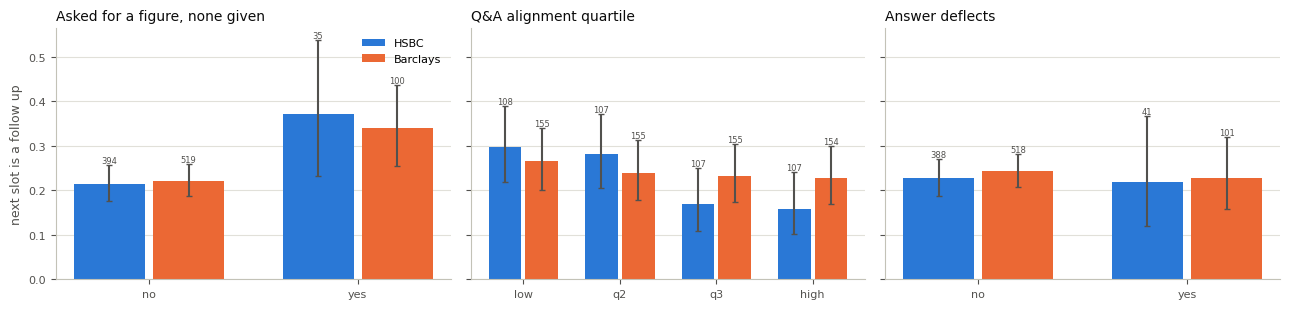

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
plot_rate_by_bank(ordered, "asked_not_given", "next_is_followup",
                  "Asked for a figure, none given", axes[0], "next slot is a follow up")
plot_rate_by_bank(ordered, "alignment_quartile", "next_is_followup",
                  "Q&A alignment quartile", axes[1])
plot_rate_by_bank(ordered, "a_deflects", "next_is_followup", "Answer deflects", axes[2])
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

A withheld figure brings the analyst back more often at both banks: 34% against 22% at Barclays, 37% against 21% at HSBC.

An answer that drifts off the question works at HSBC only (30% in the lowest alignment quartile, 16% in the highest), and its whiskers just overlap. An open refusal is followed up slightly less often at both banks. The whiskers are 95% Wilson intervals.

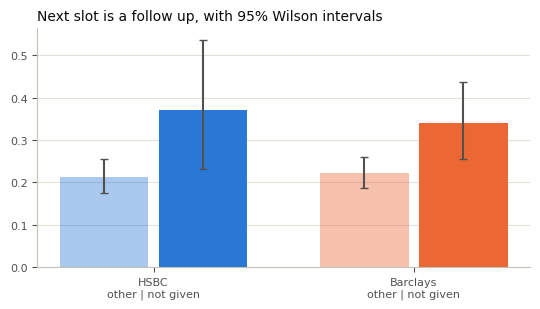

,bank,asked_not_given,n,followups,rate,ci_low,ci_high,gap,fisher_p,shuffle_p
0,hsbc,False,394,84,0.213,0.176,0.256,0.158,0.055,0.131
1,hsbc,True,35,13,0.371,0.232,0.537,0.158,0.055,0.131
2,barclays,False,519,115,0.222,0.188,0.259,0.118,0.015,0.051
3,barclays,True,100,34,0.340,0.255,0.437,0.118,0.015,0.051


In [29]:
df_followup_test = test_followup_gap(ordered)
plot_followup_gap(df_followup_test)
df_followup_test.round(3)

Barclays' gap passes Fisher's exact test (p 0.015) and falls just short when the answers are shuffled within each analyst (p 0.051). HSBC's passes neither, p 0.055 and 0.131.

HSBC rests on 35 questions, so its interval runs from 23% to 54%. Part of the gap at both banks is analysts who come back whatever the answer.

In [30]:
(df_equity.groupby(["bank", "a_deflects"])
 [["a_figures_per_100w", "a_hedges_per_100w", "qa_alignment"]].mean().round(3))

a_figures_per_100w  a_hedges_per_100w  qa_alignment
bank     a_deflects                                                     
barclays False                    0.526              0.702         0.839
         True                     0.456              0.545         0.866
hsbc     False                    0.989              0.420         0.832
         True                     0.970              0.461         0.854

Deflected answers are slightly more on topic at both banks, 0.87 against 0.84 at Barclays and 0.85 against 0.83 at HSBC, so a refusal usually answers the question it declines.

On hedging the banks differ: Barclays hedges less when it declines (0.55 against 0.70), HSBC a little more (0.46 against 0.42). So deflection and hedging stay separate signals.

## How do the six quarterly signals move, by bank?

Equity calls. Gaps are quarters with no transcript for that bank.

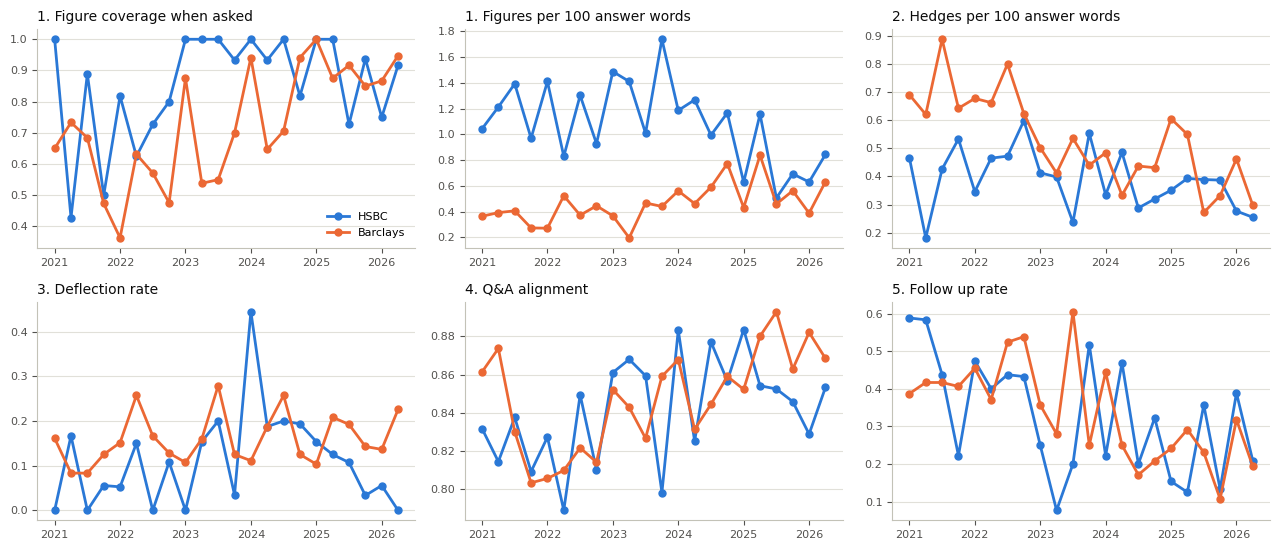

,bank,audience,followup_rate,followup_rate_adj
0,barclays,equity,0.46,-0.02
1,barclays,fixed_income,0.76,NaN
2,hsbc,equity,0.38,0.11
3,hsbc,fixed_income,0.81,0.00


In [31]:
part1_columns = ["figure_coverage", "figures_per_100w", "hedges_per_100w",
                 "deflection_rate", "qa_alignment", "followup_rate"]
part1_titles = ["1. Figure coverage when asked", "1. Figures per 100 answer words",
                "2. Hedges per 100 answer words", "3. Deflection rate",
                "4. Q&A alignment", "5. Follow up rate"]
plot_quarterly(df_quarter, part1_columns, part1_titles)

#the follow up rate against the call's length, before and after the adjustment
rho_rows = []
for (bank, audience), group in df_quarter.groupby(["bank", "audience"], observed=True):
    rho_rows.append({"bank": bank, "audience": audience,
                     "followup_rate": group.followup_rate.corr(group.n_exchanges, method="spearman"),
                     "followup_rate_adj": group.followup_rate_adj.corr(group.n_exchanges, method="spearman")})
pd.DataFrame(rho_rows).round(2)

The raw follow up rate rises with call length at Barclays (Spearman 0.46 with the number of questions). The rate adjusted for call length does not (-0.02). At HSBC the correlation falls from 0.38 to 0.11.

Longer calls give each analyst more turns, so the z-score uses the adjusted rate, `followup_rate_adj`.

# Which quarters break from the bank's own history?

Equity calls, any signal with |z| above 2.

In [32]:
z_columns = [c for c in df_quarter.columns if c.endswith("_z")]
equity_quarters = df_quarter[df_quarter.audience == "equity"].set_index(["bank", "period"])
display((equity_quarters[z_columns].abs() > 2).groupby(level="bank").sum().T)

#the first quarters of each bank have no history, so no z-score at all
scored = equity_quarters[z_columns].abs().dropna(how="all")
strongest = scored.idxmax(axis=1)
peak = scored.max(axis=1)
flagged = (pd.DataFrame({"signal": strongest, "abs_z": peak})
           .query("abs_z > 2").sort_values(["bank", "abs_z"], ascending=[True, False]))
flagged

bank,barclays,hsbc
figure_coverage_z,5,1
figures_per_100w_z,4,3
hedges_per_100w_z,4,0
deflection_rate_z,2,0
qa_alignment_z,1,2
followup_rate_adj_z,3,1


signal  abs_z
bank     period                             
barclays 2024_Q3  followup_rate_adj_z   3.97
         2022_Q2    deflection_rate_z   3.70
         2024_Q4   figures_per_100w_z   3.35
         2024_Q2  followup_rate_adj_z   3.28
         2025_Q2   figures_per_100w_z   3.02
         2023_Q3    deflection_rate_z   2.69
         2024_Q1    figure_coverage_z   2.45
         2023_Q2    hedges_per_100w_z   2.41
         2022_Q1    figure_coverage_z   2.40
         2023_Q1    figure_coverage_z   2.40
         2025_Q4  followup_rate_adj_z   2.39
         2025_Q3       qa_alignment_z   2.17
         2025_Q1    figure_coverage_z   2.10
hsbc     2022_Q2       qa_alignment_z   2.96
         2023_Q4   figures_per_100w_z   2.39
         2023_Q2  followup_rate_adj_z   2.37
         2025_Q3   figures_per_100w_z   2.36
         2025_Q1   figures_per_100w_z   2.32
         2023_Q1       qa_alignment_z   2.09

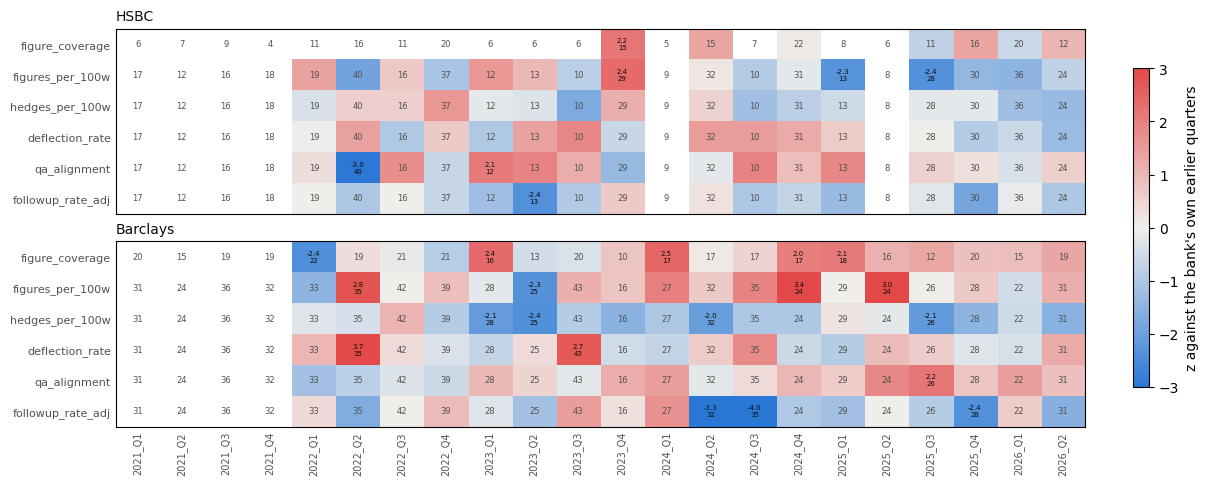

In [33]:
plot_z_heatmap(df_quarter, z_columns)

Barclays has 19 unusual readings across 13 quarters and HSBC 7 across 6. The strongest is Barclays 2024 Q3 on follow ups, z 3.97.

These are quarters to read, not conclusions. The early quarters have only four quarters of history behind them, so their flags are the weakest.

Below, each bank's strongest deflection quarter is opened: Barclays 2022 Q2 (z 3.70) and HSBC 2023 Q3 (z 1.87, under the line of 2).

In [34]:
#each bank's strongest deflection quarter, and what was declined
top_deflection = (df_quarter[df_quarter.audience == "equity"]
                  .dropna(subset=["deflection_rate_z"])
                  .sort_values("deflection_rate_z").groupby("bank").tail(1))
display(top_deflection[["bank", "period", "deflection_rate", "deflection_rate_z"]])
spike = df_signals.merge(top_deflection[["bank", "period"]], on=["bank", "period"])
spike = spike[(spike.audience == "equity") & spike.a_deflects]
spike[["bank", "period", "exchange_id", "analyst", "deflection_phrase"]]

,bank,period,deflection_rate,deflection_rate_z
42,hsbc,2023_Q3,0.2000,1.87
5,barclays,2022_Q2,0.2571,3.70


,bank,period,exchange_id,analyst,deflection_phrase
0,barclays,2022_Q2,335469fccfd8-x000,Robin Down,I'm not going to throw
1,barclays,2022_Q2,335469fccfd8-x001,Joseph Dickerson,I'm not going to guide
6,barclays,2022_Q2,335469fccfd8-x006,Rob Noble,we haven't disclosed
10,barclays,2022_Q2,335469fccfd8-x010,Chris Cant,we will come back to you
11,barclays,2022_Q2,335469fccfd8-x011,Edward Firth,can't comment
14,barclays,2022_Q2,335469fccfd8-x014,Guy Stebbings,I'm not going to guide
16,barclays,2022_Q2,335469fccfd8-x016,Rohith Chandra-Rajan,I'm not going to guide
25,barclays,2022_Q2,e6eb1ed8cfe7-x008,Andrew Coombes,do not disclose
26,barclays,2022_Q2,e6eb1ed8cfe7-x009,Andrew Coombes,do not disclose
37,hsbc,2023_Q3,d02980fb1573-x002,Joseph Dickerson,We haven't given


# Part 2: signals from FinBERT and BERTopic

Five more, built on the sentiment and topic tables. Each is checked the same way as part 1: does it move with something it should.

| # | signal | built from | grain |
|---|---|---|---|
| 6 | analyst concern | FinBERT negative minus positive on the question | exchange, quarter |
| 7 | management reassurance | `tone_gap`, answer positive minus question positive | exchange, quarter |
| 8 | script to Q&A tone drop | management positivity, prepared remarks minus Q&A | bank, quarter |
| 9 | matched analyst concern | concern from analysts who question both banks, and the gap to the other bank | bank, quarter |
| 10 | topic evasion map | signals 1 to 6 by BERTopic topic | bank, topic |

Every signal and every check is split by bank.

Three more were tried and did not carry a signal. They are kept at the end with the evidence.

## Does every exchange have a sentiment and a topic?

Everything joins on `exchange_id`. The topic signals use only questions with a subject, so short acknowledgements such as "thank you" or "okay, great" are left out.

In [35]:
df_sentiment = pd.read_parquet(SENTIMENT_FILE)
df_sentiment_exchanges = pd.read_parquet(SENTIMENT_EXCHANGES_FILE)
df_topics = pd.read_parquet(TOPICS_FILE)
df_topic_info = pd.read_parquet(TOPIC_INFO_FILE)
#the plain names replace BERTopic's word lists wherever a topic is shown
df_topic_info["label"] = df_topic_info.topic_id.map(TOPIC_NAMES).fillna(df_topic_info.label)
df_topics["topic_label"] = df_topics.topic_id.map(TOPIC_NAMES).fillna(df_topics.topic_label)
df_turns = pd.read_parquet(TURNS_FILE)

sentiment_columns = ["exchange_id", "q_positive", "q_negative", "a_positive",
                     "a_negative", "tone_gap"]
df_model = (df_signals
            .merge(df_sentiment_exchanges[sentiment_columns], on="exchange_id", how="left")
            .merge(df_topics[["exchange_id", "topic_id", "topic_label"]],
                   on="exchange_id", how="left"))
#signal 6, positive means the analyst sounded worried
df_model["q_concern"] = (df_model.q_negative - df_model.q_positive).round(4)
df_model["has_subject"] = (df_model.topic_id.ge(0)
                           & ~df_model.topic_id.isin(ACKNOWLEDGEMENT_TOPICS))

print("no sentiment:", df_model.tone_gap.isna().sum(), " no topic row:", df_model.topic_id.isna().sum())
print("outlier questions:", (df_model.topic_id == -1).sum(), " with a subject:", df_model.has_subject.sum())

no sentiment: 0  no topic row: 0
outlier questions: 0  with a subject: 1188


Yes: no exchange is missing a sentiment or a topic, and every question is assigned to a topic.

1,188 of the 1,262 questions have a clear subject. The rest are acknowledgements and are left out of the topic signals.

## What do the topics mean?

BERTopic names a topic by its most frequent words. The names used from here on were written by reading those words and a sample of questions from each topic.

In [36]:
df_topic_info[["topic_id", "label", "size", "top_words"]]

,topic_id,label,size,top_words
0,0,"Hong Kong, China and group strategy (broad)",183,hong kong; hong; kong; just; growth; wealth; q...
1,1,"Acknowledgement, no subject",74,okay; great; helpful; consider; fs; 20 fs; alr...
2,2,Structural hedge and rate sensitivity,164,hedge; just; rate; year; structural; structura...
3,3,UK business and cards (broad),156,just; cards; uk; business; think; going; ve; t...
4,4,RWAs and the Investment Bank,104,rwas; think; rwa; investment; bank; investment...
5,5,"Mortgages, lending and UK rates",79,mortgage; uk; just; rates; book; lending; grow...
6,6,"Clarification, no subject",48,just; sorry just; sorry; right; say; okay; hop...
7,7,"AT1, legacy capital and issuance",62,just; tier; ve; legacy; ve got; think; got; is...
8,8,Costs and investment spend,79,cost; costs; year; just; think; revenue; spend...
9,9,Capital and buybacks,71,capital; buybacks; just; buyback; think; quest...


Eight topics have a clear subject, from mortgages to the structural hedge. Three are broad, mostly strategy and guidance questions, and two hold acknowledgements and clarifications with no subject.

The names are a reading aid: the topic numbers behind them do not change. The model was fitted on HSBC and Barclays only, so another firm would need its own fit and its own names.

## Signals 6 and 7: do concern and reassurance move with follow ups?

Both are columns already, so the test comes first. Using the `ordered` table from part 1: does a more worried question bring the analyst back, and does management answer it more warmly?

In [37]:
model_columns = ["exchange_id", "q_concern", "tone_gap", "a_negative"]
ordered_model = ordered.merge(df_model[model_columns], on="exchange_id")
ordered_model["concern_quartile"] = quartile_within_bank(
    ordered_model, "q_concern", ["calm", "q2", "q3", "worried"])
ordered_model["gap_quartile"] = quartile_within_bank(
    ordered_model, "tone_gap", ["cooler", "q2", "q3", "warmer"])

for column, value in [("concern_quartile", "next_is_followup"),
                      ("concern_quartile", "tone_gap"),
                      ("gap_quartile", "next_is_followup"),
                      ("asked_not_given", "tone_gap")]:
    print(f"{value} by {column}")
    display(ordered_model.groupby([column, "bank"], observed=True)[value]
            .mean().unstack().round(3))

next_is_followup by concern_quartile


bank,barclays,hsbc
concern_quartile,,
calm,0.213,0.139
q2,0.200,0.206
q3,0.208,0.271
worried,0.342,0.290


tone_gap by concern_quartile


bank,barclays,hsbc
concern_quartile,,
calm,-0.021,-0.010
q2,0.109,0.159
q3,0.126,0.158
worried,0.153,0.188


next_is_followup by gap_quartile


bank,barclays,hsbc
gap_quartile,,
cooler,0.316,0.343
q2,0.219,0.215
q3,0.214,0.168
warmer,0.213,0.178


tone_gap by asked_not_given


bank,barclays,hsbc
asked_not_given,,
False,0.097,0.129
True,0.065,0.061


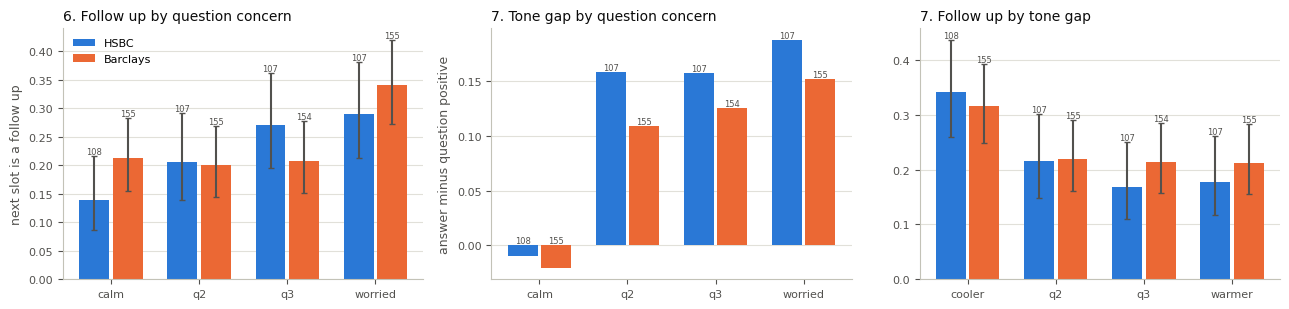

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
plot_rate_by_bank(ordered_model, "concern_quartile", "next_is_followup",
                  "6. Follow up by question concern", axes[0], "next slot is a follow up")
plot_rate_by_bank(ordered_model, "concern_quartile", "tone_gap",
                  "7. Tone gap by question concern", axes[1], "answer minus question positive")
plot_rate_by_bank(ordered_model, "gap_quartile", "next_is_followup",
                  "7. Follow up by tone gap", axes[2])
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Both move with follow ups. A worried question brings the analyst back more often: 21% in the calmest quartile of questions against 34% in the most worried at Barclays, 14% against 29% at HSBC.

A cooler answer also draws more follow ups, 32% at Barclays and 34% at HSBC, against 21% and 18% for the warmest. At both banks the calm and worried whiskers only just overlap.

## Signal 8: how far does management's tone drop from the script to the Q&A?

How much of management's positivity in the prepared remarks survives questioning. The level is always positive, the script is written to be upbeat. The movement quarter to quarter is the signal.

Both banks are computed. Barclays publishes its equity speech separately and only one is in the corpus, so for Barclays the usable series is fixed income.

mean    std    min    max  size
bank     audience                                      
barclays equity        0.232    NaN  0.232  0.232     1
         fixed_income  0.316  0.122  0.114  0.470     8
hsbc     equity        0.194  0.087 -0.038  0.348    22
         fixed_income  0.218  0.126  0.036  0.418     9

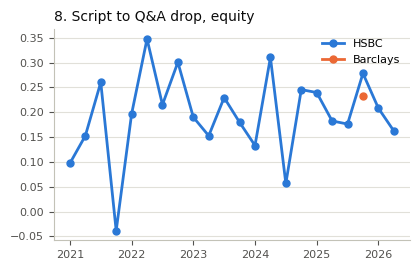

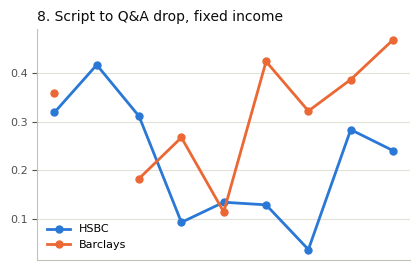

In [39]:
df_drop = script_to_qa_drop(df_sentiment, df_turns)
display(df_drop.groupby(["bank", "audience"]).script_drop
        .agg(["mean", "std", "min", "max", "size"]).round(3))
plot_quarterly(df_drop, ["script_drop"], ["8. Script to Q&A drop, equity"],
               audience="equity", n_cols=1)
plot_quarterly(df_drop, ["script_drop"], ["8. Script to Q&A drop, fixed income"],
               audience="fixed_income", n_cols=1)

HSBC's tone falls by 0.19 on average from the prepared remarks to the Q&A, over 22 equity quarters, ranging from -0.04 to 0.35.

Fixed income has a series at both banks: Barclays 0.32 over 8 quarters, HSBC 0.22 over 9. Barclays equity has one quarter, so there is no history to compare it with.

## Signal 9: is the same analyst harder on one bank?

Some analysts are sceptical whatever the bank. Taking only the analysts who questioned both banks in the same quarter holds the questioner fixed, so any gap is about the bank.

Each bank gets a row per quarter: those analysts' concern at this bank, at the other bank, and the gap. Names are matched on first initial and surname, because transcripts write both Ed Firth and Edward Firth.

16 keys merge two spellings, e.g. [array(['Andrew Coombs', 'Andy Coombs'], dtype=object), array(['Alistair Ryan', 'Alastair Ryan'], dtype=object), array(['Alvaro Serrano', 'Alvarro Serrano'], dtype=object), array(['Alastair Warr', 'Alistair Warr'], dtype=object)]


,quarters,pairs,mean_gap,more_worried_share
bank,,,,
barclays,21,127,0.013,0.429
hsbc,21,127,-0.013,0.571


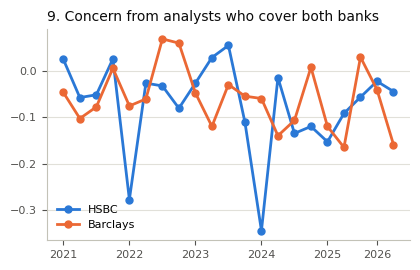

In [40]:
merged_names = (df_model.assign(analyst_key=df_model.analyst.map(analyst_key))
                .groupby("analyst_key").analyst.unique())
merged_names = merged_names[merged_names.map(len) > 1]
print(f"{len(merged_names)} keys merge two spellings, e.g. {list(merged_names.head(4))}")

df_matched = matched_analyst_concern(df_model)
display(df_matched.groupby("bank").agg(quarters=("period", "size"), pairs=("n_pairs", "sum"),
                                       mean_gap=("matched_gap", "mean"),
                                       more_worried_share=("matched_gap", lambda g: (g > 0).mean()))
        .round(3))
plot_quarterly(df_matched, ["matched_concern"],
               ["9. Concern from analysts who cover both banks"], n_cols=1)

Over 127 pairs neither bank draws clearly harder questions: the average gap is about 0.01, and Barclays gets the more worried question in 43% of pairs, HSBC in 57%.

Single quarters do separate, most in 2022 Q1, when the same analysts were far harder on Barclays. The 16 names spelt two ways were checked by hand.

## Signal 10: which topics get fewer numbers?

Joins part 1 to BERTopic. For each subject analysts raise: how often a number is asked for, how often it is given, how often management declines, and how worried the questions are.

In [41]:
df_topic_map = topic_evasion_map(df_model, df_topic_info)
enough = df_topic_map[df_topic_map.n_questions >= MIN_TOPIC_QUESTIONS]
enough.pivot(index="label", columns="bank",
             values=["n_questions", "figure_coverage", "deflection_rate"])

n_questions         \
bank                                           barclays   hsbc   
label                                                            
Capital and buybacks                               34.0   34.0   
Clarification, no subject                          21.0   18.0   
Costs and investment spend                         35.0   43.0   
Deposits and deposit pricing                       36.0   14.0   
Guidance against consensus (broad)                 81.0   26.0   
Hong Kong, China and group strategy (broad)         NaN  168.0   
Mortgages, lending and UK rates                    62.0   16.0   
Net interest income and margin guidance            59.0   22.0   
RWAs and the Investment Bank                       71.0   25.0   
Structural hedge and rate sensitivity             101.0   55.0   
UK business and cards (broad)                     123.0   18.0   

                                            figure_coverage         \
bank                                               barclays   hsbc   
label                                                                
Capital and buybacks                                  0.773  0.905   
Clarification, no subject                             0.000  1.000   
Costs and investment spend                            0.611  0.867   
Deposits and deposit pricing                          0.625  1.000   
Guidance against consensus (broad)                    0.927  0.929   
Hong Kong, China and group strategy (broad)             NaN  0.850   
Mortgages, lending and UK rates                       0.641  0.750   
Net interest income and margin guidance               0.714  1.000   
RWAs and the Investment Bank                          0.750  0.500   
Structural hedge and rate sensitivity                 0.681  0.793   
UK business and cards (broad)                         0.651  0.500   

                                            deflection_rate         
bank                                               barclays   hsbc  
label                                                               
Capital and buybacks                                  0.059  0.088  
Clarification, no subject                             0.190  0.000  
Costs and investment spend                            0.171  0.140  
Deposits and deposit pricing                          0.222  0.000  
Guidance against consensus (broad)                    0.210  0.115  
Hong Kong, China and group strategy (broad)             NaN  0.101  
Mortgages, lending and UK rates                       0.258  0.125  
Net interest income and margin guidance               0.153  0.045  
RWAs and the Investment Bank                          0.155  0.120  
Structural hedge and rate sensitivity                 0.198  0.145  
UK business and cards (broad)                         0.114  0.056

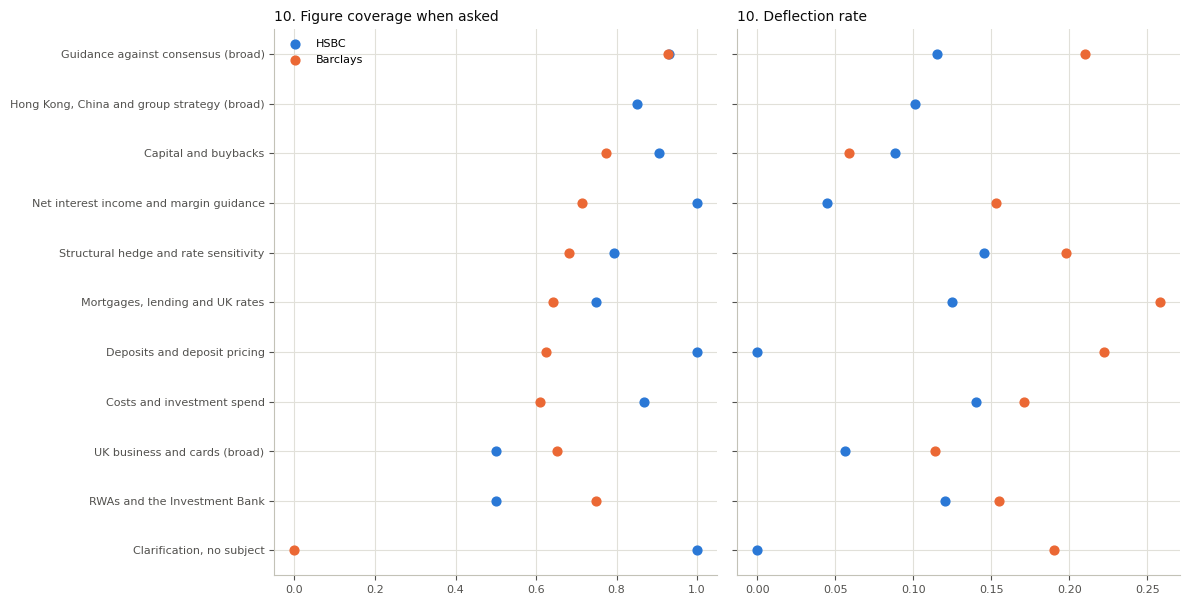

In [42]:
#topics with enough questions at either bank, ordered by the lower coverage
order = (enough.groupby("label").figure_coverage.min().sort_values().index.tolist())
fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(order) + 1.2), sharey=True)
for ax, column, title in zip(axes, ["figure_coverage", "deflection_rate"],
                             ["10. Figure coverage when asked", "10. Deflection rate"]):
    for bank in BANKS:
        rows = enough[enough.bank == bank].set_index("label").reindex(order)
        ax.scatter(rows[column], range(len(order)), s=40, color=BANK_COLOURS[bank],
                   label=BANK_NAMES[bank], zorder=3)
    style_axis(ax, title)
    ax.grid(axis="x", color=GRID_COLOUR, linewidth=0.8)
axes[0].set_yticks(range(len(order)), order, fontsize=8)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

At Barclays a requested number is given least often on costs (61%), deposits (63%) and mortgages (64%), then UK business and cards (65%) and the structural hedge (68%), against 77% for capital and buybacks. These are the subjects where the call tells a supervisor least.

HSBC is harder to read: the broad Hong Kong, China and group strategy topic holds 168 of its equity questions.

## Peer view: where does each bank give fewer numbers?

For each specific subject both banks are asked about, the share of requested figures each one gave. Broad and no-subject topics are left out, because they do not mean the same thing at both banks.

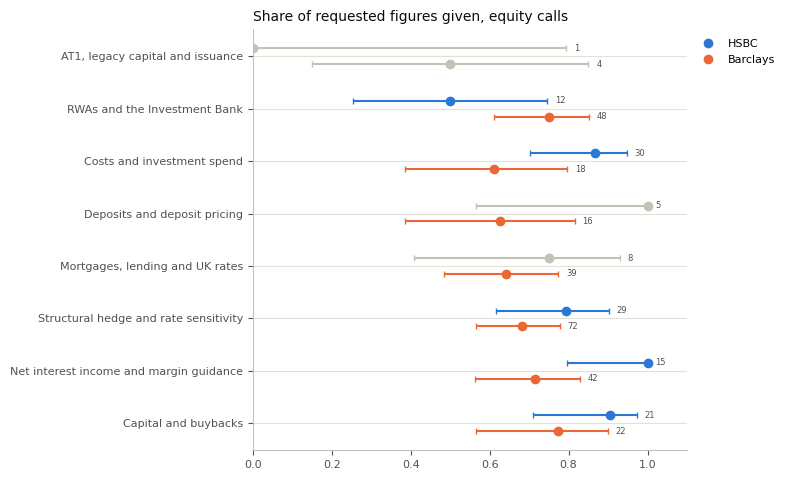

,bank,subject,n_asked,n_given,given_rate,ci_low,ci_high
0,barclays,"AT1, legacy capital and issuance",4,2,0.500,0.150,0.850
1,barclays,Capital and buybacks,22,17,0.773,0.566,0.899
2,barclays,Costs and investment spend,18,11,0.611,0.386,0.797
3,barclays,Deposits and deposit pricing,16,10,0.625,0.386,0.815
4,barclays,"Mortgages, lending and UK rates",39,25,0.641,0.484,0.773
5,barclays,Net interest income and margin guidance,42,30,0.714,0.564,0.828
6,barclays,RWAs and the Investment Bank,48,36,0.750,0.612,0.851
7,barclays,Structural hedge and rate sensitivity,72,49,0.681,0.566,0.777
8,hsbc,"AT1, legacy capital and issuance",1,0,0.000,0.000,0.793
9,hsbc,Capital and buybacks,21,19,0.905,0.711,0.973


In [43]:
df_peer = peer_disclosure(df_model)
plot_peer_disclosure(df_peer)
df_peer

On the five subjects with at least 10 requests at both banks, HSBC gives the figure more often on four: net interest income 100% against 71%, capital and buybacks 90% against 77%, costs 87% against 61%, the structural hedge 79% against 68%. On RWAs and the Investment Bank it is the other way, 50% against 75%. Every pair of intervals overlaps, so no single subject separates the banks.

Grey dots rest on fewer than 10 requests. Beyond these two banks, a peer group would be firms of the same type asked about the same subject, for example the UK banks that hold results calls.

## Which quarters break from history on signals 6 to 9?

As in part 1, each bank is compared with its own history. Signal 9 has one row per bank and quarter, so it joins the quarterly table and also keeps its own file.

In [44]:
keys = ["bank", "audience", "period"]
model_quarter = (df_model.groupby(keys, observed=True)
                 .agg(q_concern=("q_concern", "mean"), tone_gap=("tone_gap", "mean"))
                 .round(4).reset_index()
                 .merge(df_drop[keys + ["script_drop"]], how="left", on=keys)
                 .merge(df_matched[keys + ["matched_concern", "matched_gap"]],
                        how="left", on=keys))
df_quarter = (df_quarter.drop(columns=[c for c in df_quarter.columns
                                       if c.removesuffix("_z") in model_quarter.columns
                                       and c not in keys])
              .merge(model_quarter, how="left", on=keys)
              .sort_values(keys).reset_index(drop=True))
for column in ["q_concern", "tone_gap", "script_drop", "matched_concern", "matched_gap"]:
    #gaps and thin quarters are skipped, so neither breaks the history
    guarded = df_quarter[column].where(small_quarter_mask(df_quarter, column))
    df_quarter[f"{column}_z"] = (guarded.groupby([df_quarter.bank, df_quarter.audience], observed=True)
                                 .transform(lambda s: history_zscore(s.dropna()).reindex(s.index)))

keep = ["exchange_id", "q_concern", "tone_gap", "topic_id", "topic_label", "has_subject"]
df_signals = df_signals.drop(columns=[c for c in keep[1:] if c in df_signals.columns]).merge(
    df_model[keep], on="exchange_id", how="left")

write_table(df_signals, SIGNALS_FILE)
write_table(df_quarter, SIGNALS_QUARTER_FILE)
write_table(df_topic_map, SIGNALS_TOPIC_FILE)
write_table(df_matched, SIGNALS_MATCHED_FILE)
print(df_signals.shape, df_quarter.shape, df_topic_map.shape, df_matched.shape)

(1262, 24) (63, 28) (24, 10) (42, 7)


The quarterly table holds signals 1 to 9: 63 bank-quarters by 28 columns.

The tone drop z-score skips quarters with no prepared remarks, so gaps in HSBC's series do not break its history.

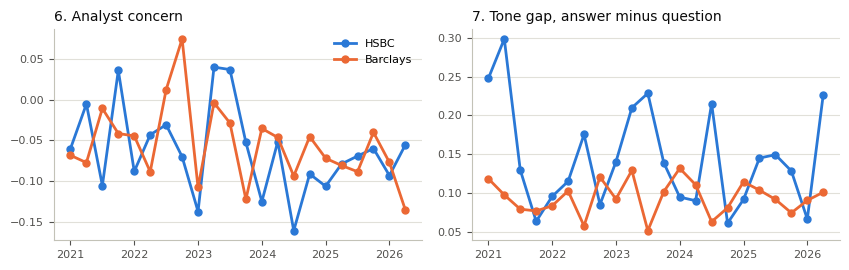

,bank,period,signal,z
3,barclays,2022_Q1,matched_gap_z,10.52
10,barclays,2022_Q3,matched_concern_z,3.46
12,barclays,2022_Q4,q_concern_z,3.30
35,barclays,2024_Q1,matched_gap_z,2.79
8,barclays,2022_Q3,q_concern_z,2.37
9,barclays,2022_Q3,tone_gap_z,-2.19
74,hsbc,2022_Q1,matched_gap_z,-10.52
73,hsbc,2022_Q1,matched_concern_z,-5.69
115,hsbc,2024_Q3,q_concern_z,-2.16


In [45]:
plot_quarterly(df_quarter, ["q_concern", "tone_gap"],
               ["6. Analyst concern", "7. Tone gap, answer minus question"], n_cols=2)

new_z = ["q_concern_z", "tone_gap_z", "script_drop_z", "matched_concern_z", "matched_gap_z"]
equity_quarters = df_quarter[df_quarter.audience == "equity"].set_index(["bank", "period"])
flagged_model = (equity_quarters[new_z].stack().rename("z")
                 .rename_axis(["bank", "period", "signal"]).reset_index())
flagged_model = flagged_model[flagged_model.z.abs() > 2].assign(abs_z=lambda d: d.z.abs())
flagged_model.sort_values(["bank", "abs_z"], ascending=[True, False]).drop(columns="abs_z")

The largest break is 2022 Q1, when analysts who cover both banks were far harder on Barclays than on HSBC (gap z 10.52, and -10.52 from HSBC's side). Barclays 2022 Q3 flags on three signals at once: matched concern z 3.46, concern 2.37 and tone gap -2.19.

The heatmap below puts every z column on one page, per bank. Red is above the bank's own history, blue below.

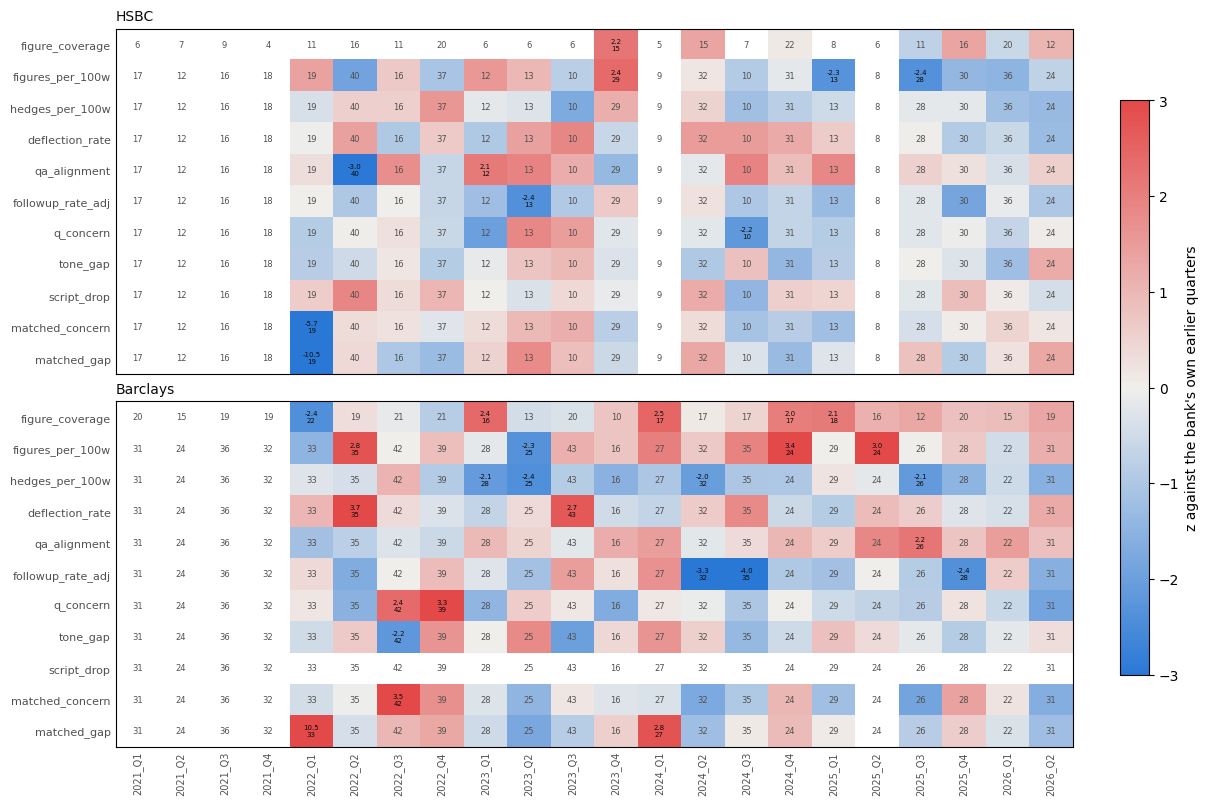

In [46]:
all_z = [c for c in df_quarter.columns if c.endswith("_z")]
plot_z_heatmap(df_quarter, all_z)

# Part 3: from signals to evidence

The signals only point to where to look, and the transcript stays the evidence. Part 3 turns them into a reading list for each bank.

## Signal 11: which topics is the market asking about more?

Each topic's share of the questions is compared with its share the last time it came up, per bank. Years are used rather than quarters, since a single quarter holds too few questions.

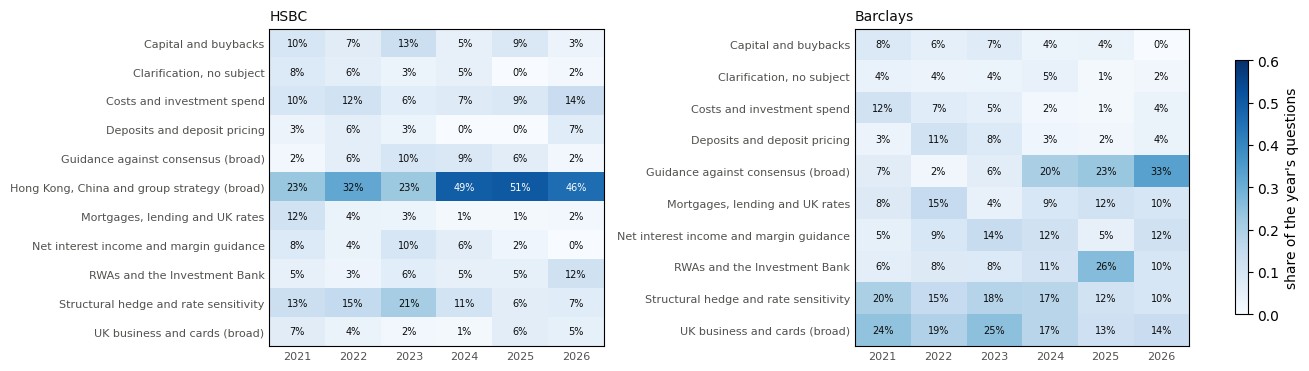

,bank,year,label,n_questions,share,share_change,q_concern
75,hsbc,2024,"Hong Kong, China and group strategy (broad)",40,0.494,0.268,-0.071
22,barclays,2025,RWAs and the Investment Bank,27,0.262,0.152,-0.060
69,barclays,2024,Guidance against consensus (broad),22,0.202,0.140,-0.087
71,barclays,2026,Guidance against consensus (broad),17,0.333,0.100,-0.089
73,hsbc,2022,"Hong Kong, China and group strategy (broad)",33,0.317,0.087,-0.018
55,barclays,2022,Deposits and deposit pricing,16,0.113,0.080,0.029
95,hsbc,2026,RWAs and the Investment Bank,7,0.119,0.068,-0.008
122,hsbc,2023,Capital and buybacks,8,0.129,0.062,-0.083


In [47]:
df_attention = topic_attention(df_model, df_topic_info)
plot_attention(df_attention)

#each bank's biggest risers, with the concern of those questions alongside
risers = (df_attention[df_attention.n_questions >= 5]
          .sort_values("share_change", ascending=False).groupby("bank").head(4))
risers[["bank", "year", "label", "n_questions", "share", "share_change", "q_concern"]]

The biggest rises are in the broad topics: Hong Kong, China and group strategy reaches 49% of HSBC's questions in 2024, and guidance against consensus 33% of Barclays' in 2026. Barclays RWAs and the Investment Bank rise to 26% in 2025.

The narrower topics are easier to read. Barclays deposits rise in 2022 as interest rates went up, and HSBC capital and buybacks rise in 2023. Concern on these questions stays below zero apart from Barclays deposits in 2022, so more attention is mostly not more worry.

## Signal 12: which exchanges should be read first?

This goes from the quarterly averages back to single exchanges. Each equity exchange scores one point per signal that fires, and the highest scores are read first.

In [48]:
df_flags = stack_flags(ordered_model, df_quarter, all_z)
display(df_flags.groupby(["n_flags", "bank"]).size().unstack(fill_value=0))

#ties on flags go to the more worried question
df_shortlist = (df_flags.sort_values(["n_flags", "q_concern"], ascending=False)
                .groupby("bank").head(SHORTLIST_SIZE))
df_shortlist.groupby("bank").n_flags.describe()[["count", "min", "mean", "max"]]

bank,barclays,hsbc
n_flags,,
0,60,106
1,209,167
2,210,106
3,99,39
4,32,10
5,8,1
6,1,0


,count,min,mean,max
bank,,,,
barclays,15.0,4.0,4.666667,6.0
hsbc,15.0,3.0,3.800000,5.0


The shortlist has 4 to 6 flags per exchange at Barclays and 3 to 5 at HSBC.

Most exchanges fire one or two. Barclays has more unusual quarters (19 readings against 7), but the shortlist is ranked within each bank, so HSBC is not crowded out.

## Signal 13: can Gemma 3 extract the concern without inventing metrics?

Gemma 3 is asked for five fields, on the shortlist only. It extracts and does not judge. Every metric it lists is checked against the exchange text, so an invented one shows up.

In [49]:
to_extract = df_shortlist[["exchange_id", "bank", "period"]].merge(
    df_exchanges[["exchange_id", "question_text", "answer_text"]], on="exchange_id")
df_llm = ground_metrics(extract_exchanges(to_extract), df_exchanges)
df_llm = df_llm.merge(df_shortlist[["exchange_id", "bank"]], on="exchange_id")
for field in ["risk_or_uncertainty", "forward_looking_statement"]:
    df_llm[field] = df_llm[field].map(clean_field)

#does the model follow the format, and does what it lists exist in the text
df_llm.groupby("bank").agg(
    exchanges=("exchange_id", "size"),
    json_valid=("llm_json_valid", "mean"),
    with_risk=("risk_or_uncertainty", lambda s: s.notna().mean()),
    with_forward_look=("forward_looking_statement", lambda s: s.notna().mean()),
    metrics=("n_metrics", "sum"),
    metrics_grounded=("n_metrics_grounded", "sum")).round(2)

,exchanges,json_valid,with_risk,with_forward_look,metrics,metrics_grounded
bank,,,,,,
barclays,15,1.0,0.33,0.53,19,19
hsbc,15,1.0,0.20,0.53,22,22


In [50]:
#the metrics the check could not find, read these by hand
df_llm.loc[df_llm.ungrounded_metrics.ne(""), ["bank", "exchange_id", "ungrounded_metrics"]]

,bank,exchange_id,ungrounded_metrics
0,barclays,4e98e4abfb11-x012,RoTE
12,barclays,9ba7893c81ce-x008,ROE


Gemma 3 invents one metric: ROE, which is not in its exchange.

Of the items Gemma lists, 41 hold a figure and all 41 are found in the text. Labels such as NII or a year are listed but not counted. RoTE is right too, the exchange says "return on tangible" and the check is a literal text match. Gemma finds a risk in 8 of 30 exchanges and guidance in 16.


## What does a shortlisted exchange look like?

One row per shortlisted exchange: the flags, the scores, Gemma's fields and the keys back to the source document.

In [51]:
review_columns = ["exchange_id", "doc_sha256", "bank", "period", "analyst", "analyst_firm",
                  "n_flags", "flags", "q_concern", "tone_gap", "qa_alignment",
                  "topic_label"] + LLM_FIELDS + ["n_metrics", "n_metrics_grounded"]
df_review = (df_shortlist
             .merge(df_exchanges[["exchange_id", "doc_sha256", "analyst_firm"]],
                    on="exchange_id")
             .merge(df_model[["exchange_id", "topic_label"]], on="exchange_id")
             .merge(df_llm.drop(columns="bank"), on="exchange_id", how="left"))
df_review = df_review[review_columns].sort_values(
    ["bank", "n_flags", "q_concern"], ascending=[True, False, False])
#lists are stored as text so the csv and parquet agree
df_review["financial_metrics_mentioned"] = df_review.financial_metrics_mentioned.map(
    lambda m: "; ".join(map(str, m)) if isinstance(m, list) else m)
write_table(df_review, SIGNALS_REVIEW_FILE)
write_table(df_attention, SIGNALS_ATTENTION_FILE)
df_review.groupby("bank").head(3)[["bank", "period", "analyst", "flags",
                                   "analyst_concern", "risk_or_uncertainty"]]

,bank,period,analyst,flags,analyst_concern,risk_or_uncertainty
0,barclays,2023_Q3,Edward Firth,asked not given; deflects; off topic; worried;...,The analyst questions the projected exit margi...,None
1,barclays,2024_Q3,Jonathan Pierce,asked not given; deflects; off topic; worried;...,The analyst questioned whether the rate sensit...,None
2,barclays,2022_Q3,Andrew Coombs,asked not given; off topic; worried; analyst c...,"diverging trends between NII and fees, potenti...",None
8,hsbc,2022_Q2,Tom Rayner,asked not given; deflects; worried; analyst ca...,The analyst wants guidance on non-interest inc...,None
13,hsbc,2022_Q2,Raul Sinha,deflects; worried; analyst came back; unusual ...,The analyst is concerned about HSBC's capital ...,"market shifts, currency movements, future inte..."
17,hsbc,2022_Q1,Manus Costello,off topic; worried; analyst came back; unusual...,the analyst's concern about HSBC’s confidence ...,None


In [52]:
#each bank's top exchange
for bank in BANKS:
    inspect_exchange(df_review[df_review.bank == bank].exchange_id.iloc[0])
    print("\n" + "=" * 80 + "\n")

HSBC 2022_Q2 | Tom Rayner | Numis
flags: asked not given; deflects; worried; analyst came back; unusual quarter

QUESTION
Thank you. Hi, everyone. Since you're feeling so charitable and you're giving specific guidance on net interest income, costs, returns, I could possibly back out what you're thinking on non-interest income, but I just wondered if you could give us any colour on what you're thinking in terms of the main drivers: Covid restrictions, trade, what's going on in capital markets, Chinese GDP, all of those things to look at. But seems to be a missing piece of the P&L that we don't have now.

ANSWER
Tom, you know how much Ewen likes giving guidance on NII. Now, you're asking him to give guidance on NFI as well. Tom, if my chief accountant was here, we'd be running dangerously close to giving a profit forecast. But the only thing I would say is, when you run your calculations for 2023, do you think about all of the one-offs that we've had this year, including the negative ins

The HSBC exchange is a declined forecast: a request for colour on non-interest income, answered with "I'm not going to give you a non-NII forecast, but nice try", and the analyst back in the next slot.

The Barclays one is a worried question on the exit margin and a possible gap to consensus, answered with "I'm not going to comment on the exit rate from Q4". Gemma marks no risk in either. It summarises what was said, not what was avoided.

## Read-first sheet: which exchanges to open, and what to ask

One row per shortlisted exchange, in plain words, with the page to open. An exchange is flagged for each of six rules: a figure asked for and not given, a deflecting phrase, an answer in the bank's least on-topic quarter of answers, a question in its most worried quarter, the analyst back in the next slot, and a call where any signal is unusual for the bank.

In [53]:
df_documents = pd.read_parquet(DOCUMENTS_FILE)
df_read_first = build_read_first_sheet(df_review, df_exchanges, df_documents)
with pd.option_context("display.max_colwidth", None):
    display(df_read_first.drop(columns=["Link", "doc_sha256"]))

,Bank,Quarter,Analyst firm,Subject,What was asked,What management said,Why flagged,Question to put to the firm,Metrics checked,Source
0,Barclays,2023 Q3,KBW,Structural hedge and rate sensitivity,"The analyst questions the projected exit margin of 290 bps for next year and its potential impact on net interest income (NII) and return on tangible equity (RoTE), suggesting a possible £500-600 million difference from consensus forecasts.",Management avoids commenting on the specific exit rate and reiterates that they provided a range based on anticipated deposit trends.,asked not given; deflects; off topic; worried; analyst came back; unusual quarter,The analyst asked for a figure on structural hedge and rate sensitivity and got none. Can the firm give it?,3 of 3 found in the text,"Barclays 2023 Q3 transcript, p. 10"
1,Barclays,2024 Q3,Jefferies,Structural hedge and rate sensitivity,"The analyst questioned whether the rate sensitivity table only considered a 25 basis point yield pickup from hedging and ignored any other potential impact, specifically regarding reinvesting £40bn of hedge at 25 basis points less.",Management acknowledged the small impact in year one and offered to discuss it further privately.,asked not given; deflects; off topic; worried; unusual quarter,The analyst asked for a figure on structural hedge and rate sensitivity and got none. Can the firm give it?,3 of 3 found in the text,"Barclays 2024 Q3 transcript, p. 7"
2,Barclays,2022 Q3,Citi,UK business and cards (broad),"diverging trends between NII and fees, potential one-off fees in Q222, calibration of IFRS 9 scenarios in US vs UK","Management attributes the divergence in revenue lines to initial costs related to GAP in the current quarter, expecting recovery in Q4. They state the US situation is relatively straightforward.",asked not given; off topic; worried; analyst came back; unusual quarter,The analyst asked for a figure on uk business and cards (broad) and got none. Can the firm give it?,0 of 0 found in the text,"Barclays 2022 Q3 transcript, p. 7"
3,Barclays,2024 Q2,Autonomous,Net interest income and margin guidance,"The analyst wants to understand the specific pricing actions taken on BUK deposits and the level of average deposit rates, as well as expectations for US consumer income progression.","Management does not disclose deposit costs but highlights progress in broadening savings offerings, growth in fixed-term deposits, stabilization of market share after losing it last year, and flat current account balances. Regarding US consumer, they anticipate seasonal trends with higher income and impairment in Q4, and expect gradual deposit growth alongside actions to address headwinds like late fees.",asked not given; deflects; worried; analyst came back; unusual quarter,The analyst asked for a figure on net interest income and margin guidance and got none. Can the firm give it?,1 of 1 found in the text,"Barclays 2024 Q2 transcript, p. 5"
4,Barclays,2025 Q2,UBS,Guidance against consensus (broad),"The analyst questioned the Tesco Bank revenue disclosure, stating that the combined total of £279 million (cards plus Tesco) was only £61 million more than the standalone cards division (£60 million), implying an annualised revenue of £250 million. They also raised concern about whether the expected £400 million after acquisition is being accurately reflected in the slide.","Management reiterated their expectation for Tesco to achieve an NII of c.£500 million, including funding synergies and stated they would return to the analyst with further clarification if needed.",deflects; off topic; worried; analyst came back; unusual quarter,Management declined to discuss part of guidance against consensus (broad). What can it share now?,6 of 6 found in the text,"Barclays 2025 Q2 transcript, p. 8"
5,Barclays,2023 Q3,Morgan Stanley,Net interest income and margin guidance,The analyst is questioning Barclays' deposit guidance relative to competitor commentary suggesting slowe

The sheet lists 30 exchanges, 15 per bank. In 16 of them a figure was asked for and not given, so the question to put to the firm is simply to ask for it again.

The summaries are Gemma's, and all 41 figures they name are found in the transcript. The source is the page where the question starts, and the link opens the bank's own PDF.


## Call card: what happened on each bank's latest calls?

One card per results call, for each bank's two latest equity calls. Concern is unusual when it sits more than two standard deviations from the bank's own earlier calls, with at least four earlier calls and ten questions behind it. The other bank's reading for the same quarter is shown beside it.

In [54]:
latest_periods = (df_model[df_model.audience == "equity"].groupby("bank").period
                  .apply(lambda p: sorted(p.unique())[-2:]))
for bank in BANKS:
    for period in latest_periods[bank]:
        print(f"{BANK_NAMES[bank]} {period.replace('_', ' ')}")
        with pd.option_context("display.max_colwidth", None):
            display(build_call_card(bank, period, df_quarter, df_model, df_flags, df_exchanges))

HSBC 2026 Q1


,
Questions,36 analyst questions
Top subjects,"Hong Kong, China and group strategy (broad) (14); RWAs and the Investment Bank (6); Structural hedge and rate sensitivity (4)"
Analyst concern,usual for HSBC (z -0.6); usual at Barclays the same quarter (z -0.6)
Figures held back,5 of 20 requested figures not given
Read first,"Aman Rakkar, Barclays, 3 flags, HSBC 2026 Q1 transcript, p. 9"


HSBC 2026 Q2


,
Questions,24 analyst questions
Top subjects,"Hong Kong, China and group strategy (broad) (13); Costs and investment spend (5); Mortgages, lending and UK rates (1)"
Analyst concern,usual for HSBC (z 0.1); usual at Barclays the same quarter (z -1.9)
Figures held back,1 of 12 requested figures not given
Read first,"Amit Goel, Mediobanca, 2 flags, HSBC 2026 Q2 transcript, p. 9"


Barclays 2026 Q1


,
Questions,22 analyst questions
Top subjects,"Guidance against consensus (broad) (6); UK business and cards (broad) (6); Mortgages, lending and UK rates (3)"
Analyst concern,usual for Barclays (z -0.6); usual at HSBC the same quarter (z -0.6)
Figures held back,2 of 15 requested figures not given
Read first,"Amit Goel, Mediobanca, 2 flags, Barclays 2026 Q1 transcript, p. 4"


Barclays 2026 Q2


,
Questions,31 analyst questions
Top subjects,Guidance against consensus (broad) (11); Net interest income and margin guidance (4); Structural hedge and rate sensitivity (3)
Analyst concern,usual for Barclays (z -1.9); usual at HSBC the same quarter (z 0.1)
Figures held back,1 of 19 requested figures not given
Read first,"Sachin Nayar, Goldman Sachs, 2 flags, Barclays 2026 Q2 transcript, p. 14"


None of the four latest calls is unusual for its bank: concern sits between z -1.9 and 0.1 at both banks, so neither quarter points to a market-wide move either. HSBC 2026 Q1 held back the most figures, 5 of the 20 asked for.

The read-first line is the exchange with the most flags on that call, with the page where the question starts.

# What a PRA supervisor gets from this

The brief asks whether results calls add to the PRA's risk assessment of a firm. The published figures say what happened. The Q&A shows where the market is pressing, and how management holds up when it does.

| # | signal | the supervisor's question | why it matters |
|---|---|---|---|
| 1 | figure coverage | asked for a number, does management give one? | disclosure quality. A bank that stops quantifying an area is a question for the next meeting |
| 2 | hedging | how firm is the guidance? | uncertainty management admits to in its own words |
| 3 | deflection | what will management not discuss? | where the firm itself sees sensitivity. The phrase is kept so it can be read |
| 4 | alignment | did the answer address the question? | the quieter version of a deflection |
| 5 | follow up | did the analyst accept the answer? | the closest thing to a second opinion inside the transcript |
| 6 | concern | how worried do analysts sound? | analysts look for weak spots for a living. An outside early warning |
| 7 | tone gap | is management warmer than the question? | reassurance to check against the numbers |
| 8 | script to Q&A drop | does tone fall when the script ends? | how much of the prepared tone survives questioning |
| 9 | matched concern | is the same analyst harder on one bank? | peer benchmarking, with the questioner held fixed |
| 10 | topic evasion map | which subjects get fewer numbers? | points to the risk area, not only the quarter |
| 11 | topic attention | what is the market asking about more? | attention moves before the figures do |
| 12 | stacked flags | which exchanges to read first? | triage for a team covering around 1,500 firms |
| 13 | Gemma extraction | what was the concern, the risk, the guidance? | the brief's summarisation question, with every metric checked |

None of these says a bank is in trouble. FinBERT scores language, not solvency, and a z-score flags a quarter, not a problem.

The use is triage. The z heatmap says which calls to open, the shortlist which exchanges, and `inspect_exchange` puts the source text on screen. The judgement stays with the supervisor.

Do results calls add information? The evidence leans yes but is not firm: when a requested figure is withheld, the analyst comes back 34% of the time at Barclays and 37% at HSBC, against 22% and 21% otherwise.

Barclays' gap passes Fisher's test (p 0.015) and falls just short within each analyst (0.051). HSBC's rests on 35 questions and passes neither (0.055 and 0.131).

# Tried and did not work

Three more measures were built and checked, and none moves with anything it should. Each is kept with its evidence so the result can be rerun.

## Tried 1 and 2: do topic drift and concentration carry a signal?

Drift is the Jensen-Shannon distance between a quarter's topic mix and the bank's earlier quarters. Concentration is the entropy of the mix: a crisis call should collapse onto one subject.

In [55]:
df_mix = topic_mix_signals(df_model)
print("questions with a subject per bank-quarter")
display(df_mix.groupby("bank").n_questions.describe()[["min", "50%", "max"]])
for bank in BANKS:
    print(f"{BANK_NAMES[bank]} correlation with the question count")
    display(df_mix[df_mix.bank == bank][["n_questions", "topic_entropy", "topic_drift"]]
            .corr().round(2).loc[["topic_entropy", "topic_drift"], "n_questions"].to_frame())

questions with a subject per bank-quarter


,min,50%,max
bank,,,
barclays,16.0,28.0,43.0
hsbc,8.0,17.0,37.0


HSBC correlation with the question count


,n_questions
topic_entropy,0.42
topic_drift,-0.55


Barclays correlation with the question count


,n_questions
topic_entropy,0.69
topic_drift,-0.25


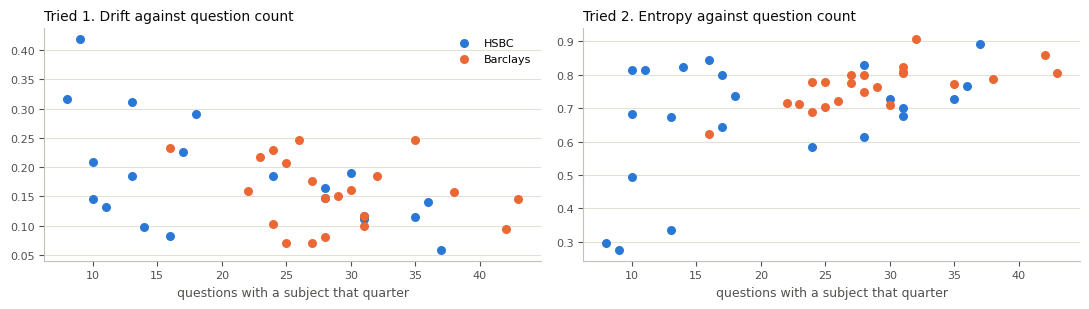

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, column, title in zip(axes, ["topic_drift", "topic_entropy"],
                             ["Tried 1. Drift against question count",
                              "Tried 2. Entropy against question count"]):
    for bank in BANKS:
        rows = df_mix[df_mix.bank == bank]
        ax.scatter(rows.n_questions, rows[column], s=30, color=BANK_COLOURS[bank],
                   label=BANK_NAMES[bank])
    style_axis(ax, title)
    ax.set_xlabel("questions with a subject that quarter", fontsize=9, color=TEXT_SECONDARY)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Neither carries a signal: both mostly track how many questions had a subject. HSBC's drift correlates -0.55 with that count and Barclays' -0.25, entropy 0.42 and 0.69.

With a median of 17 subject questions a quarter at HSBC and 28 at Barclays, the topic mix is mostly noise.

## Tried 3: does adjusting concern for the analyst change it?

Signal 6 minus the analyst's own average over their other questions to the same bank (leave one out), so a habitually sceptical analyst does not read as concern.

In [57]:
adjusted_rows = []
for bank in BANKS:
    bank_model = df_model[df_model.bank == bank].copy()
    questions_by_analyst = bank_model.groupby("analyst").q_concern
    analyst_count = questions_by_analyst.transform("size")
    #leave one out, so a question is not compared with itself
    analyst_baseline = ((questions_by_analyst.transform("sum") - bank_model.q_concern)
                        / (analyst_count - 1))
    bank_model["q_concern_adjusted"] = (
        bank_model.q_concern
        - analyst_baseline.where(analyst_count >= MIN_ANALYST_QUESTIONS))
    by_quarter = (bank_model[bank_model.audience == "equity"].groupby("period")
                  [["q_concern", "q_concern_adjusted"]].mean())
    adjusted_rows.append({
        "bank": bank,
        "analyst_share_of_variance": round(questions_by_analyst.transform("mean").var()
                                           / bank_model.q_concern.var(), 3),
        "quarterly_raw_vs_adjusted": round(by_quarter.corr().iloc[0, 1], 2)})
pd.DataFrame(adjusted_rows)

,bank,analyst_share_of_variance,quarterly_raw_vs_adjusted
0,hsbc,0.169,0.88
1,barclays,0.106,0.95


Adjusting for the analyst changes little: the adjusted quarterly series tracks the raw one at 0.88 at HSBC and 0.95 at Barclays.

The analyst explains 17% of the variance in concern at HSBC and 11% at Barclays. Signal 9, which holds the analyst fixed across banks, is the version of this idea that adds something.